In [1]:
!pip install category_encoders


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split
from category_encoders import TargetEncoder
from imblearn.over_sampling import SMOTE

In [3]:
df = pd.read_csv('/content/KaggleV2-May-2016.csv')

In [4]:
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [5]:
df.shape

(110527, 14)

**Data preprocessing**

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


In [7]:
# --- 2. Rename columns for consistency and ease of use ---
# The dataset has some columns with capitalization and a hyphen in 'No-show'.
df.rename(columns={
    'Hipertension': 'Hypertension',
    'Handcap': 'Handicap',
    'SMS_received': 'SMSReceived',
    'No-show': 'NoShow'
}, inplace=True)
print("\nColumns renamed.")
print(df.columns.tolist())


Columns renamed.
['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay', 'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMSReceived', 'NoShow']


In [8]:
# --- 3. Convert date/time columns to datetime objects ---
# 'ScheduledDay' and 'AppointmentDay' are currently objects.
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])
print("\n'ScheduledDay' and 'AppointmentDay' converted to datetime objects.")
df.info()


'ScheduledDay' and 'AppointmentDay' converted to datetime objects.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype              
---  ------          --------------   -----              
 0   PatientId       110527 non-null  float64            
 1   AppointmentID   110527 non-null  int64              
 2   Gender          110527 non-null  object             
 3   ScheduledDay    110527 non-null  datetime64[ns, UTC]
 4   AppointmentDay  110527 non-null  datetime64[ns, UTC]
 5   Age             110527 non-null  int64              
 6   Neighbourhood   110527 non-null  object             
 7   Scholarship     110527 non-null  int64              
 8   Hypertension    110527 non-null  int64              
 9   Diabetes        110527 non-null  int64              
 10  Alcoholism      110527 non-null  int64              
 11  Handicap        110527 non-null  int64              
 12  SMSR

In [9]:
# Extract Day of Week for AppointmentDay
df['Appointment_Day_of_Week'] = df['AppointmentDay'].dt.day_name()
print("\n'Appointment_Day_of_Week' feature created.")


'Appointment_Day_of_Week' feature created.


In [10]:

# Calculate Waiting Time (difference between ScheduledDay and AppointmentDay)
# FIX: Use .dt.normalize() to ensure both dates are at midnight before subtracting
# This results in a Timedelta Series (timedelta64[ns]) which supports .dt.days
df['Waiting_Time_Days'] = (df['AppointmentDay'].dt.normalize() - df['ScheduledDay'].dt.normalize()).dt.days
print("'Waiting_Time_Days' feature created.")


'Waiting_Time_Days' feature created.


In [11]:
# Handle cases where Waiting_Time_Days is negative
df['Waiting_Time_Days'] = df['Waiting_Time_Days'].apply(lambda x: x if x >= 0 else 0)
print("Negative 'Waiting_Time_Days' values handled (set to 0).")


Negative 'Waiting_Time_Days' values handled (set to 0).


In [12]:
# Extract month of appointment
df['Appointment_Month'] = df['AppointmentDay'].dt.month
print("'Appointment_Month' feature created.")

'Appointment_Month' feature created.


In [13]:
# --- 5. Handle outliers or inconsistencies ---

# Age: Check for invalid ages (e.g., negative age).
invalid_age_rows = df[df['Age'] < 0]
if not invalid_age_rows.empty:
    print(f"\nFound {len(invalid_age_rows)} rows with invalid 'Age' (< 0).")
    df = df[df['Age'] >= 0]
    print("Removed rows with invalid age.")



Found 1 rows with invalid 'Age' (< 0).
Removed rows with invalid age.


In [14]:

# --- 6. Encode categorical features ---

# Gender: Convert 'F' and 'M' to numerical (e.g., 0 and 1)
df['Gender'] = df['Gender'].map({'F': 0, 'M': 1})
print("\n'Gender' encoded (F=0, M=1).")

# NoShow: Convert 'No' and 'Yes' to numerical (e.g., 0 for 'No', 1 for 'Yes')
df['NoShow'] = df['NoShow'].map({'No': 0, 'Yes': 1})
print("'NoShow' encoded (No=0, Yes=1).")


'Gender' encoded (F=0, M=1).
'NoShow' encoded (No=0, Yes=1).


In [15]:
# Binary features (Scholarship, Hypertension, Diabetes, Alcoholism, SMSReceived):
binary_cols = ['Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMSReceived']
for col in binary_cols:
    if df[col].dtype == 'int64' or df[col].dtype == 'float64':
        df[col] = df[col].astype(int)
    else:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
print(f"Binary features {binary_cols} ensured to be integer type.")


Binary features ['Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMSReceived'] ensured to be integer type.


In [16]:
# Appointment_Day_of_Week: One-hot encode (Neighbourhood will be target encoded later)
df = pd.get_dummies(df, columns=['Appointment_Day_of_Week'], drop_first=True)
print("\n'Appointment_Day_of_Week' one-hot encoded.")


'Appointment_Day_of_Week' one-hot encoded.


In [17]:

# --- 7. Drop unnecessary columns ---
df.drop(['PatientId', 'AppointmentID', 'ScheduledDay', 'AppointmentDay'], axis=1, inplace=True)
print("\nDropped 'PatientId', 'AppointmentID', 'ScheduledDay', 'AppointmentDay' columns.")


Dropped 'PatientId', 'AppointmentID', 'ScheduledDay', 'AppointmentDay' columns.


In [18]:
# --- 8. Final Check ---
print(f"\nFinal shape after preprocessing: {df.shape}")
print("\nFinal Data Info:")
df.info()
print("\nFirst 5 rows of preprocessed data:")
print(df.head())


Final shape after preprocessing: (110526, 17)

Final Data Info:
<class 'pandas.core.frame.DataFrame'>
Index: 110526 entries, 0 to 110526
Data columns (total 17 columns):
 #   Column                             Non-Null Count   Dtype 
---  ------                             --------------   ----- 
 0   Gender                             110526 non-null  int64 
 1   Age                                110526 non-null  int64 
 2   Neighbourhood                      110526 non-null  object
 3   Scholarship                        110526 non-null  int64 
 4   Hypertension                       110526 non-null  int64 
 5   Diabetes                           110526 non-null  int64 
 6   Alcoholism                         110526 non-null  int64 
 7   Handicap                           110526 non-null  int64 
 8   SMSReceived                        110526 non-null  int64 
 9   NoShow                             110526 non-null  int64 
 10  Waiting_Time_Days                  110526 non-null  int6

In [19]:
# --- 1. Check for Class Imbalance in the Target Variable (NoShow) ---
print("\n1. Target Variable (NoShow) Distribution:")
print(df['NoShow'].value_counts())


1. Target Variable (NoShow) Distribution:
NoShow
0    88207
1    22319
Name: count, dtype: int64


In [20]:

print("\nNoShow Distribution (Percentage):")
print(df['NoShow'].value_counts(normalize=True) * 100)



NoShow Distribution (Percentage):
NoShow
0    79.806561
1    20.193439
Name: proportion, dtype: float64


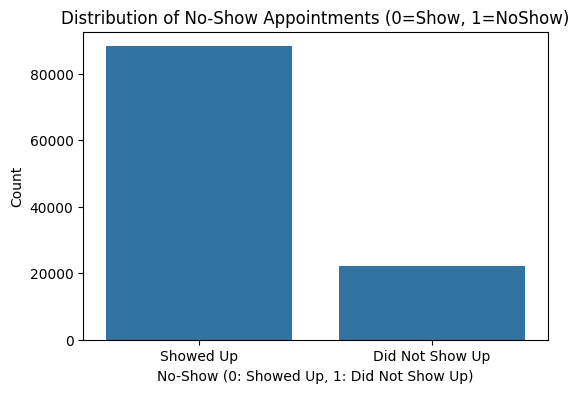

In [21]:

plt.figure(figsize=(6, 4))
sns.countplot(x='NoShow', data=df)
plt.title('Distribution of No-Show Appointments (0=Show, 1=NoShow)')
plt.xlabel('No-Show (0: Showed Up, 1: Did Not Show Up)')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Showed Up', 'Did Not Show Up'])
plt.show()

**Data visualization**


 Distribution of Numerical Features:


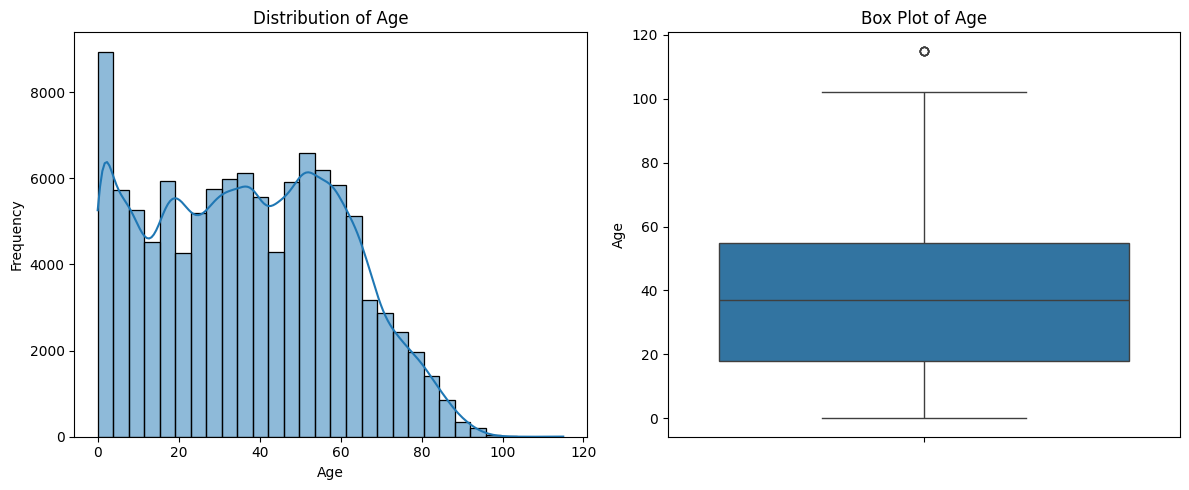

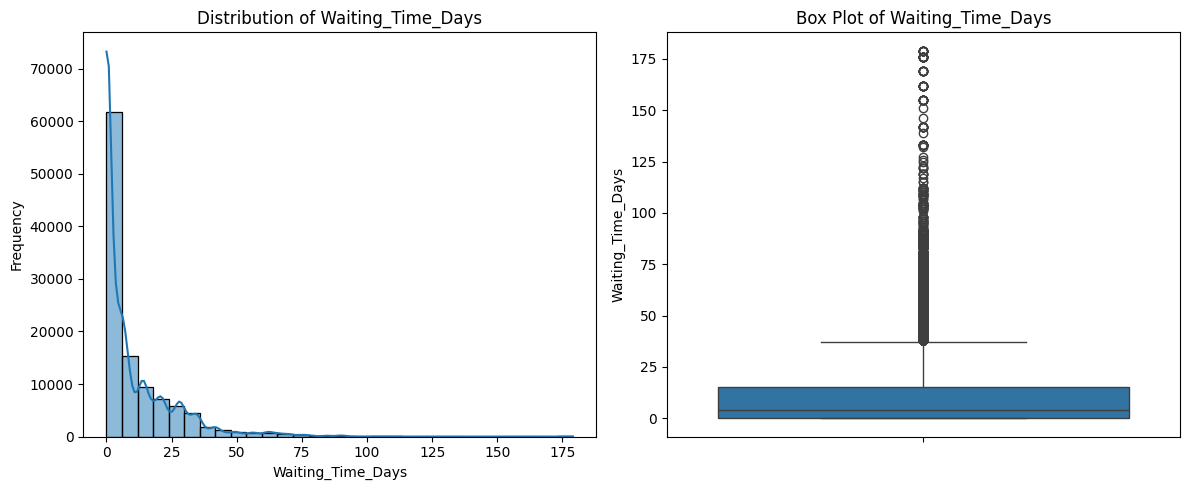

/tmp/ipython-input-2043891730.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=df, palette='viridis')


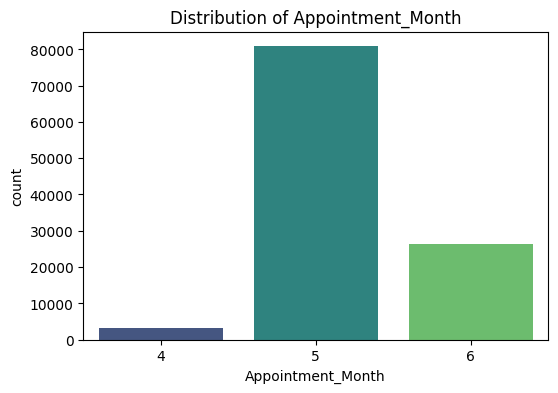

/tmp/ipython-input-2043891730.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=df, palette='viridis')


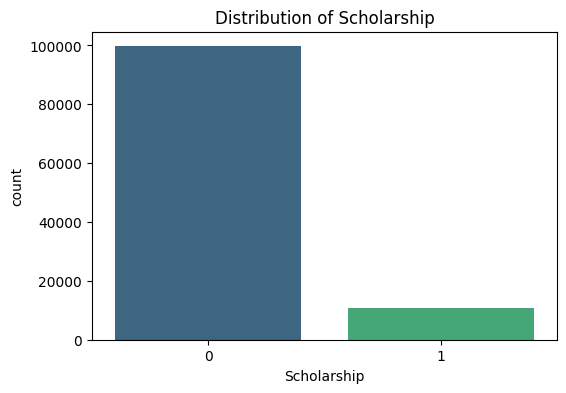

/tmp/ipython-input-2043891730.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=df, palette='viridis')


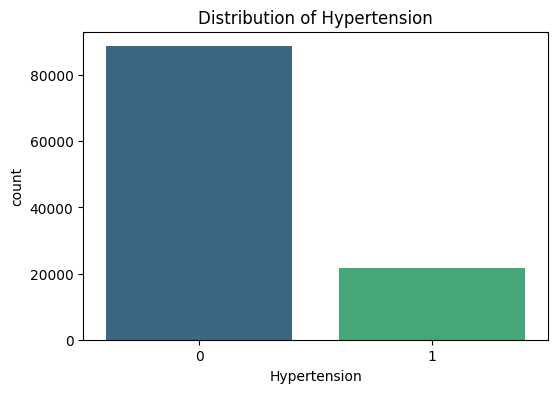

/tmp/ipython-input-2043891730.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=df, palette='viridis')


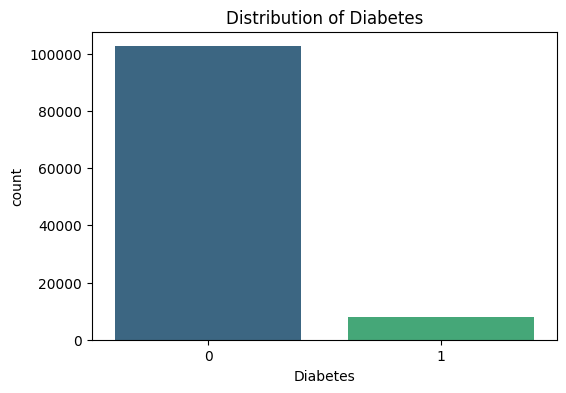

/tmp/ipython-input-2043891730.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=df, palette='viridis')


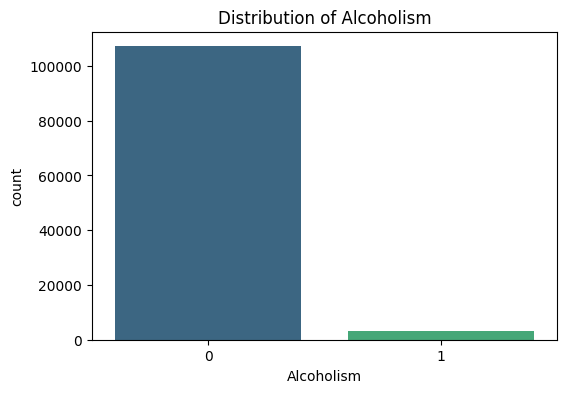

/tmp/ipython-input-2043891730.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=df, palette='viridis')


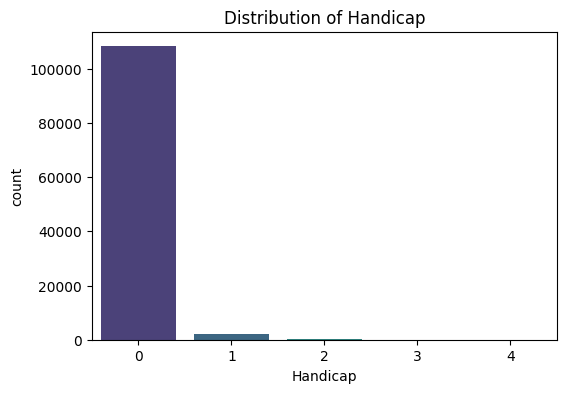

/tmp/ipython-input-2043891730.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=df, palette='viridis')


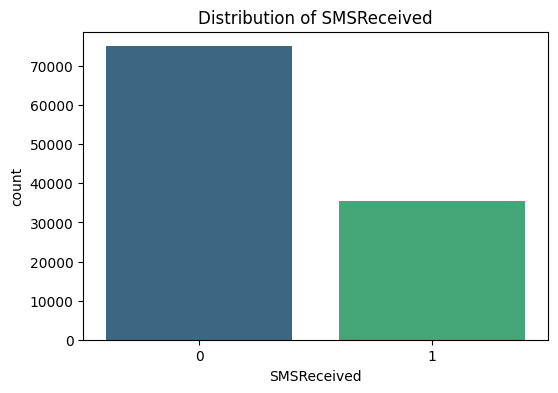

/tmp/ipython-input-2043891730.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=df, palette='viridis')


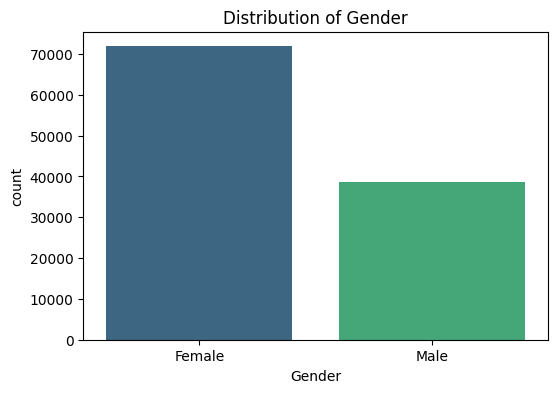

In [22]:
# 3.2 Understand Distributions of Numerical Features
print("\n Distribution of Numerical Features:")
# Updated list to reflect features after initial preprocessing
numerical_features = ['Age', 'Waiting_Time_Days', 'Appointment_Month', 'Scholarship', 'Hypertension',
                      'Diabetes', 'Alcoholism', 'Handicap', 'SMSReceived', 'Gender']

for feature in numerical_features:
    if feature in df.columns:
        # For truly continuous or high-cardinality numerical features
        if df[feature].nunique() > 5 or df[feature].dtype == 'float64':
            plt.figure(figsize=(12, 5))
            plt.subplot(1, 2, 1)
            sns.histplot(df[feature], kde=True, bins=30)
            plt.title(f'Distribution of {feature}')
            plt.xlabel(feature)
            plt.ylabel('Frequency')

            plt.subplot(1, 2, 2)
            sns.boxplot(y=df[feature])
            plt.title(f'Box Plot of {feature}')
            plt.ylabel(feature)
            plt.tight_layout()
            plt.show()
        else: # For low cardinality integers, including binary
            plt.figure(figsize=(6, 4))
            sns.countplot(x=feature, data=df, palette='viridis')
            plt.title(f'Distribution of {feature}')
            # Custom x-axis labels for Gender and Handicap
            if feature == 'Gender':
                plt.xticks(ticks=[0, 1], labels=['Female', 'Male'])
            elif feature == 'Handicap':
                if df['Handicap'].nunique() <= 2:
                    plt.xticks(ticks=[0, 1], labels=['No', 'Yes'])
            plt.show()



3.3 Correlation Matrix (Core Numerical and Binary Features):


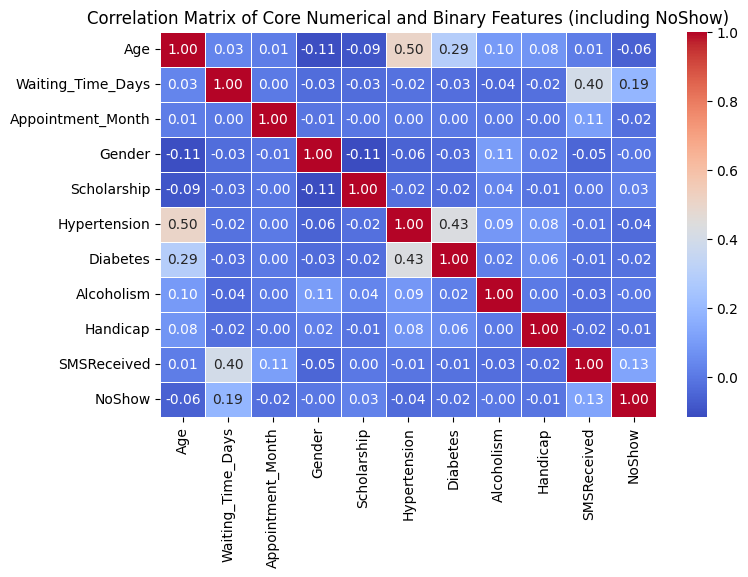

In [23]:
# 3.3 Correlation Analysis (on selected numerical/binary features)
print("\n3.3 Correlation Matrix (Core Numerical and Binary Features):")
# Including 'NoShow' to see correlations with the target
core_numerical_and_binary = ['Age', 'Waiting_Time_Days', 'Appointment_Month',
                             'Gender', 'Scholarship', 'Hypertension', 'Diabetes',
                             'Alcoholism', 'Handicap', 'SMSReceived', 'NoShow']
relevant_cols = [col for col in core_numerical_and_binary if col in df.columns]

if len(relevant_cols) > 1:
    correlation_matrix = df[relevant_cols].corr()
    plt.figure(figsize=(8, 5))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
    plt.title('Correlation Matrix of Core Numerical and Binary Features (including NoShow)')
    plt.show()
else:
    print("Not enough numerical/binary columns to compute correlation matrix.")



3.4 Relationship with Target Variable (NoShow):


/tmp/ipython-input-2729177837.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='NoShow', y=feature, data=df, palette='pastel')


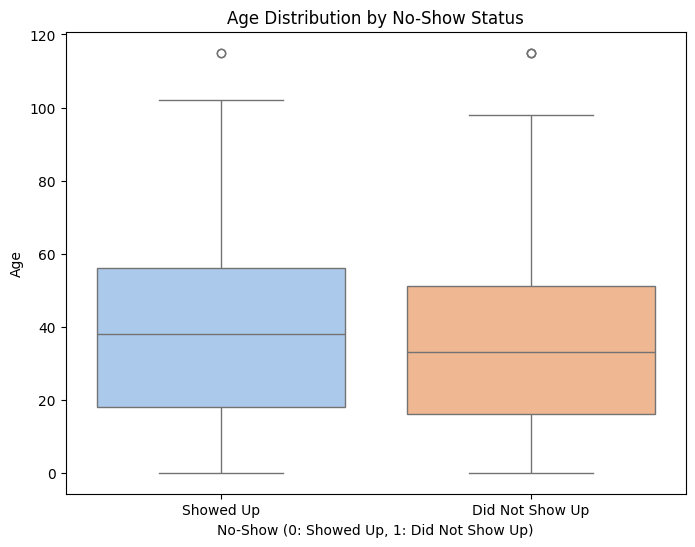

/tmp/ipython-input-2729177837.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='NoShow', y=feature, data=df, palette='pastel')


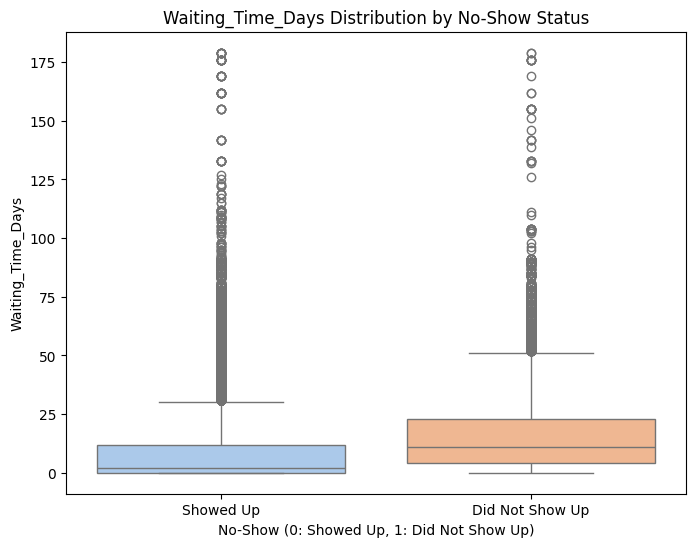

/tmp/ipython-input-2729177837.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='NoShow', y=feature, data=df, palette='pastel')


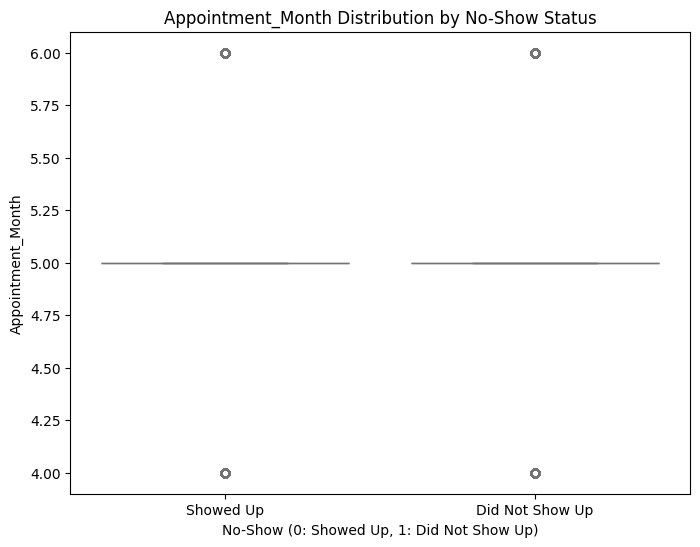

In [24]:
# 3.4 Relationship with Target Variable (NoShow)
print("\n3.4 Relationship with Target Variable (NoShow):")

# 3.4.1 Numerical Features vs. NoShow (using box plots)
for feature in ['Age', 'Waiting_Time_Days', 'Appointment_Month']:
    if feature in df.columns:
        plt.figure(figsize=(8, 6))
        sns.boxplot(x='NoShow', y=feature, data=df, palette='pastel')
        plt.title(f'{feature} Distribution by No-Show Status')
        plt.xlabel('No-Show (0: Showed Up, 1: Did Not Show Up)')
        plt.ylabel(feature)
        plt.xticks(ticks=[0, 1], labels=['Showed Up', 'Did Not Show Up'])
        plt.show()

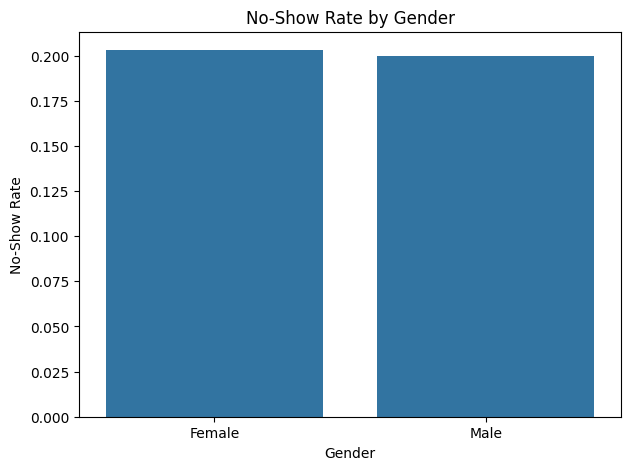

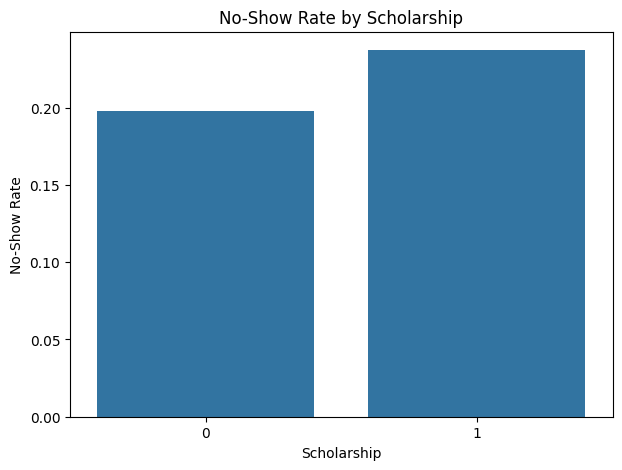

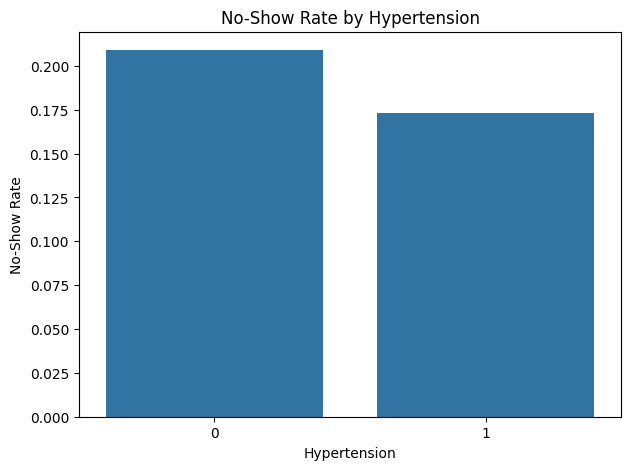

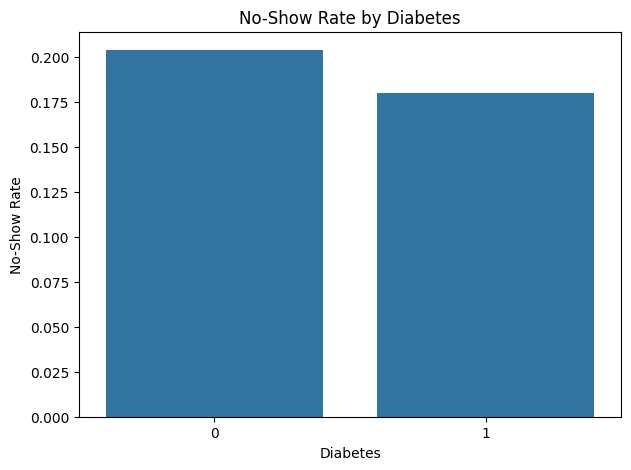

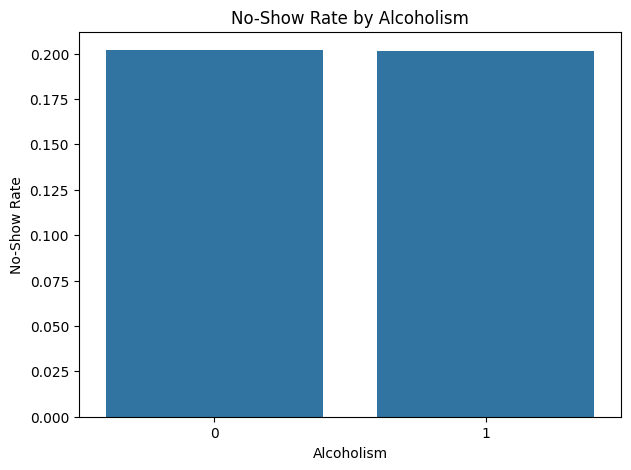

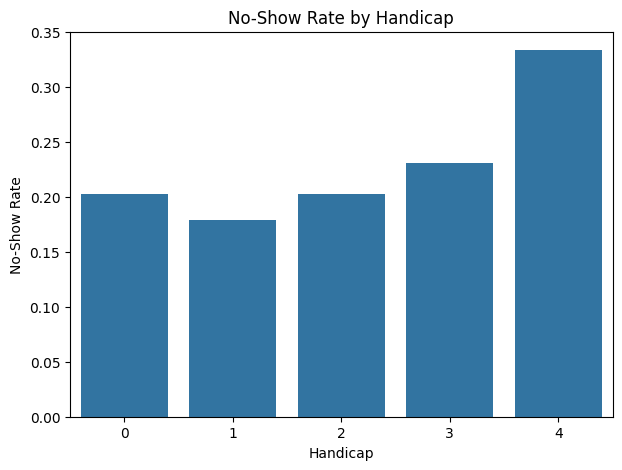

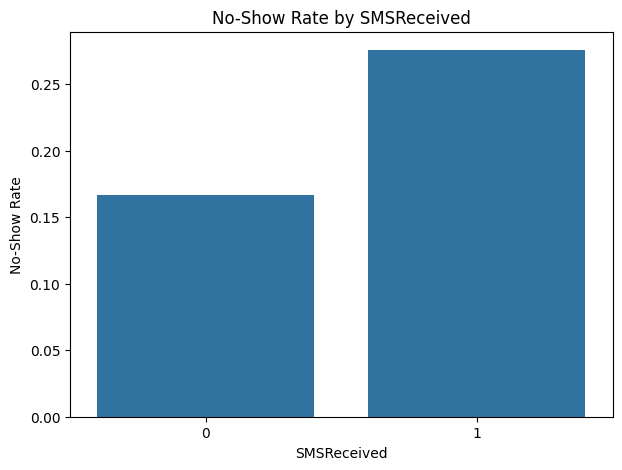

In [25]:
# 4.2. Binary/Categorical Features vs. NoShow Rate
binary_features = ['Gender', 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMSReceived']

for feature in binary_features:
    if feature in df.columns:
        plt.figure(figsize=(7, 5))
        # Calculate the NoShow rate for each category
        noshow_rate = df.groupby(feature)['NoShow'].mean().reset_index()
        sns.barplot(x=feature, y='NoShow', data=noshow_rate)
        plt.title(f'No-Show Rate by {feature}')
        plt.xlabel(feature)
        plt.ylabel('No-Show Rate')
        # Custom x-axis labels for Gender and Handicap if applicable
        if feature == 'Gender':
            plt.xticks(ticks=[0, 1], labels=['Female', 'Male'])
        elif feature == 'Handicap':
            # Assuming 0 is not handicapped, 1 is handicapped. If multiple levels >1 exist, this needs adjustment.
            if df['Handicap'].nunique() <= 2: # Binary handicap
                plt.xticks(ticks=[0, 1], labels=['No', 'Yes'])
            else: # Multiple handicap levels, show numbers
                pass # Use default numeric labels
        plt.show()


No-Show Rate by Appointment Day of Week:


/tmp/ipython-input-2530929238.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Day', y='NoShow_Rate', data=noshow_by_day_df, palette='viridis')


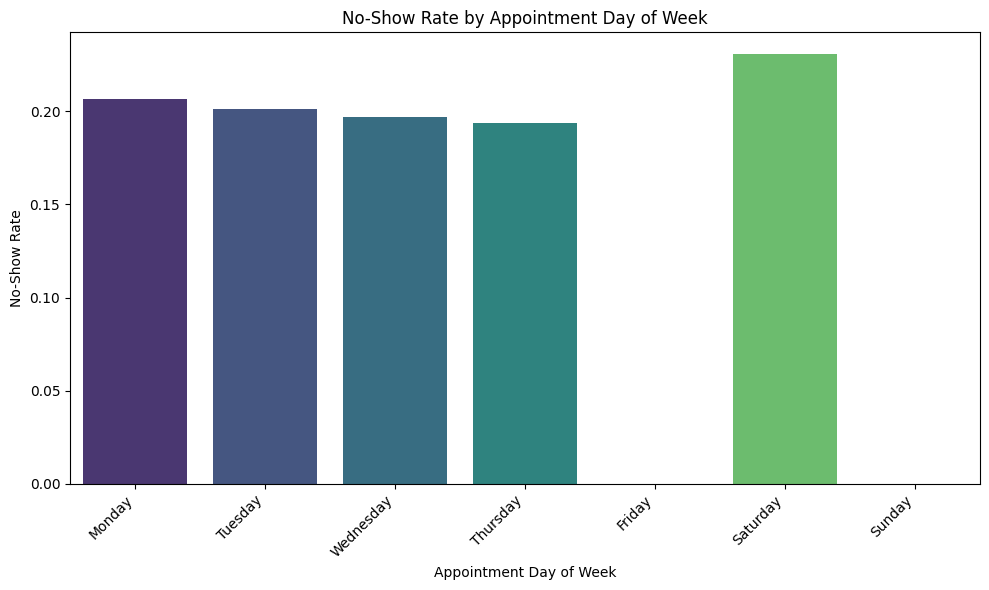

In [26]:
# 4.3. One-Hot Encoded 'Appointment_Day_of_Week' vs. NoShow Rate
# Identify the one-hot encoded columns for Appointment_Day_of_Week
day_of_week_cols = [col for col in df.columns if col.startswith('Appointment_Day_of_Week_')]

if day_of_week_cols:
    print("\nNo-Show Rate by Appointment Day of Week:")
    noshow_by_day = []
    for col in day_of_week_cols:
        day_name = col.replace('Appointment_Day_of_Week_', '')
        # Calculate the mean NoShow where this day is 1 (i.e., this is the appointment day)
        if 1 in df[col].unique(): # Only if the value 1 exists for the day
            rate = df[df[col] == 1]['NoShow'].mean()
            noshow_by_day.append({'Day': day_name, 'NoShow_Rate': rate})

    if noshow_by_day:
        noshow_by_day_df = pd.DataFrame(noshow_by_day)
        # Sort by day of week for better visualization (Mon-Sun order)
        day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
        noshow_by_day_df['Day'] = pd.Categorical(noshow_by_day_df['Day'], categories=day_order, ordered=True)
        noshow_by_day_df = noshow_by_day_df.sort_values('Day')

        plt.figure(figsize=(10, 6))
        sns.barplot(x='Day', y='NoShow_Rate', data=noshow_by_day_df, palette='viridis')
        plt.title('No-Show Rate by Appointment Day of Week')
        plt.xlabel('Appointment Day of Week')
        plt.ylabel('No-Show Rate')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
    else:
        print("No 'Appointment_Day_of_Week_' columns found with '1' values for analysis.")
else:
    print("No 'Appointment_Day_of_Week_' columns found.")



In [27]:
# --- Helper function to handle duplicate columns (CRITICAL FIX) ---
def handle_duplicate_columns(df_input):
    cols = pd.Series(df_input.columns)
    duplicated_cols_names = cols[cols.duplicated()].unique()
    if len(duplicated_cols_names) > 0:
        print(f"  Found duplicate column names: {duplicated_cols_names.tolist()}. Renaming for uniqueness.")
        new_cols = []
        for col_name in df_input.columns:
            if col_name in duplicated_cols_names:
                count = 0
                temp_name = col_name
                while temp_name in new_cols:
                    count += 1
                    temp_name = f"{col_name}_{count}"
                new_cols.append(temp_name)
            else:
                new_cols.append(col_name)
        df_input.columns = new_cols
    return df_input

In [28]:
# Separate features (X) and target (y)
X = df.drop('NoShow', axis=1)
y = df['NoShow']

print(f"Initial X shape: {X.shape}")

Initial X shape: (110526, 16)


In [29]:

# 4.1 Apply duplicate column handling to X before further manipulation
print("\n Applying initial duplicate column handling to X (ensuring no OHE or previous step created non-unique names)...")
X = handle_duplicate_columns(X.copy())
print(f"X shape after initial duplicate column handling: {X.shape}")


 Applying initial duplicate column handling to X (ensuring no OHE or previous step created non-unique names)...
X shape after initial duplicate column handling: (110526, 16)


In [30]:

# 4.2 Identify Redundant Features (Correlation-based on core numerical/binary features)
print("\n Identifying Highly Correlated Features (on current core numerical/binary features in X):")
# Only include numerical columns that are not one-hot encoded for this initial correlation check
core_numerical_binary_cols = ['Age', 'Waiting_Time_Days', 'Appointment_Month', 'Gender',
                                  'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMSReceived']
relevant_numerical_cols_for_corr = [col for col in core_numerical_binary_cols if col in X.columns]

if len(relevant_numerical_cols_for_corr) > 1:
    correlation_matrix_X = X[relevant_numerical_cols_for_corr].corr().abs()
    upper_tri = correlation_matrix_X.where(np.triu(np.ones(correlation_matrix_X.shape), k=1).astype(bool))
    to_drop_high_corr = [column for column in upper_tri.columns if any(upper_tri[column] > 0.9)]

    if to_drop_high_corr:
        print(f"  Highly correlated features (corr > 0.9) identified for potential removal: {to_drop_high_corr}")
        # DECISION: For this pipeline, we will *not* automatically drop highly correlated features here.
        # This allows models (e.g., tree-based) to potentially use them, or for later manual selection.
        # For linear models, dropping one of the pair is often necessary.
    else:
        print("  No highly correlated features (corr > 0.9) found among the core numerical/binary features in X.")
else:
    print("  Not enough relevant numerical/binary columns in X to check for high correlation.")


 Identifying Highly Correlated Features (on current core numerical/binary features in X):
  No highly correlated features (corr > 0.9) found among the core numerical/binary features in X.


In [31]:

# 4.3 Create Interaction Terms
print("\n Creating Interaction Terms:")
# Ensure columns exist before creating interaction terms
if 'Age' in X.columns and 'Hypertension' in X.columns:
    X['Age_x_Hypertension'] = X['Age'] * X['Hypertension']
    print("  Created 'Age_x_Hypertension' interaction term.")
if 'SMSReceived' in X.columns and 'Waiting_Time_Days' in X.columns:
    X['SMSReceived_x_Waiting_Time_Days'] = X['SMSReceived'] * X['Waiting_Time_Days']
    print("  Created 'SMSReceived_x_Waiting_Time_Days' interaction term.")
if 'Gender' in X.columns and 'Alcoholism' in X.columns:
    X['Gender_x_Alcoholism'] = X['Gender'] * X['Alcoholism']
    print("  Created 'Gender_x_Alcoholism' interaction term.")
print(f"X shape after creating interaction terms: {X.shape}")


 Creating Interaction Terms:
  Created 'Age_x_Hypertension' interaction term.
  Created 'SMSReceived_x_Waiting_Time_Days' interaction term.
  Created 'Gender_x_Alcoholism' interaction term.
X shape after creating interaction terms: (110526, 19)


In [32]:

# 4.4 Generating Polynomial Features
print("\n Generating Polynomial Features:")
poly_features_to_expand = ['Age', 'Waiting_Time_Days']
poly_degree = 2

# Filter to ensure only existing columns are passed to PolynomialFeatures
poly_features_to_expand = [col for col in poly_features_to_expand if col in X.columns]

if poly_features_to_expand:
    poly = PolynomialFeatures(degree=poly_degree, include_bias=False)
    poly_data = poly.fit_transform(X[poly_features_to_expand])
    poly_feature_names = poly.get_feature_names_out(poly_features_to_expand)

    poly_df = pd.DataFrame(poly_data, columns=poly_feature_names, index=X.index)

    # CRITICAL FIX: Apply duplicate column handling to poly_df's own output if needed
    print("  Applying duplicate column handling to polynomial features DataFrame (poly_df) output...")
    poly_df = handle_duplicate_columns(poly_df.copy())

    X = pd.concat([X, poly_df], axis=1)

    # CRITICAL FIX: Apply duplicate column handling to X *again* after concat
    # This catches any potential duplicates arising from the concat operation itself,
    # as PolynomialFeatures can sometimes recreate original columns or names might clash.
    print("\n  Applying duplicate column handling to X (after concatting polynomial features)...")
    X = handle_duplicate_columns(X.copy())

    print(f"  Generated polynomial features (degree={poly_degree}) for: {poly_features_to_expand}")
    # Print examples of newly added polynomial features (heuristically, these are the new ones)
    print(f"  Example polynomial features added: {[col for col in poly_feature_names if col not in poly_features_to_expand]}")

else:
    print("  Selected polynomial features not found in X.")
print(f"X shape after adding polynomial features: {X.shape}")




 Generating Polynomial Features:
  Applying duplicate column handling to polynomial features DataFrame (poly_df) output...

  Applying duplicate column handling to X (after concatting polynomial features)...
  Found duplicate column names: ['Age', 'Waiting_Time_Days']. Renaming for uniqueness.
  Generated polynomial features (degree=2) for: ['Age', 'Waiting_Time_Days']
  Example polynomial features added: ['Age^2', 'Age Waiting_Time_Days', 'Waiting_Time_Days^2']
X shape after adding polynomial features: (110526, 24)


**Train test split**

In [33]:
# Perform the train-test split *before* fitting the TargetEncoder to prevent data leakage.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nOriginal dataset shape: {X.shape}")
print(f"Original target distribution:\n{y.value_counts(normalize=True)}")
print(f"\nTraining set shape (X_train): {X_train.shape}")
print(f"Training target distribution (y_train):\n{y_train.value_counts(normalize=True)}")
print(f"\nTest set shape (X_test): {X_test.shape}")
print(f"Test target distribution (y_test):\n{y_test.value_counts(normalize=True)}")
print("\n" + "="*50 + "\n")


Original dataset shape: (110526, 24)
Original target distribution:
NoShow
0    0.798066
1    0.201934
Name: proportion, dtype: float64

Training set shape (X_train): (88420, 24)
Training target distribution (y_train):
NoShow
0    0.798066
1    0.201934
Name: proportion, dtype: float64

Test set shape (X_test): (22106, 24)
Test target distribution (y_test):
NoShow
0    0.798064
1    0.201936
Name: proportion, dtype: float64




In [34]:
# --- Step 5: Target Encoding for High-Cardinality Categorical Features (Neighbourhood) ---

print("--- Step 5: Target Encoding for 'Neighbourhood' ---")

# IMPORTANT: Fit the encoder ONLY on the training data to prevent data leakage.
# Then transform both training and test sets.
if 'Neighbourhood' in X_train.columns and X_train['Neighbourhood'].dtype == 'object':
    print(f"  'Neighbourhood' column found in training data (dtype: {X_train['Neighbourhood'].dtype}). Applying Target Encoding.")

    encoder = TargetEncoder(cols=['Neighbourhood'])

    # Fit and transform on training data
    X_train['Neighbourhood'] = encoder.fit_transform(X_train, y_train)['Neighbourhood']

    # Transform test data using the *fitted* encoder from the training data
    X_test['Neighbourhood'] = encoder.transform(X_test)['Neighbourhood']

    print("  Target encoded 'Neighbourhood' column successfully for both training and test sets.")
    print(f"  New 'Neighbourhood' dtype in X_train: {X_train['Neighbourhood'].dtype}")
else:
    print("  'Neighbourhood' column not found or not of object/string type in training data. Skipping Target Encoding.")
    print("  Please ensure 'Neighbourhood' is kept as an object/string type in initial preprocessing steps for target encoding.")

print(f"\nX_train shape after Target Encoding: {X_train.shape}")
print(f"X_test shape after Target Encoding: {X_test.shape}")
print("\n" + "="*50 + "\n")

--- Step 5: Target Encoding for 'Neighbourhood' ---
  'Neighbourhood' column found in training data (dtype: object). Applying Target Encoding.
  Target encoded 'Neighbourhood' column successfully for both training and test sets.
  New 'Neighbourhood' dtype in X_train: float64

X_train shape after Target Encoding: (88420, 24)
X_test shape after Target Encoding: (22106, 24)




In [35]:
# --- Step 6: Handling Class Imbalance (SMOTE) ---

print("--- Step 6: Handling Class Imbalance (SMOTE) on Training Data ---")
sm = SMOTE(random_state=42)
# X_train must be fully numeric before SMOTE. TargetEncoder should have converted 'Neighbourhood'.
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

print(f"\nOriginal X_train shape: {X_train.shape}")
print(f"Original y_train distribution:\n{y_train.value_counts()}")
print(f"\nAfter SMOTE, X_train_res shape: {X_train_res.shape}")
print(f"After SMOTE, y_train_res distribution:\n{y_train_res.value_counts()}")
print("\n" + "="*50 + "\n")

--- Step 6: Handling Class Imbalance (SMOTE) on Training Data ---

Original X_train shape: (88420, 24)
Original y_train distribution:
NoShow
0    70565
1    17855
Name: count, dtype: int64

After SMOTE, X_train_res shape: (141130, 24)
After SMOTE, y_train_res distribution:
NoShow
1    70565
0    70565
Name: count, dtype: int64




In [36]:
# --- Step 7: Scaling Numerical Features ---
print("--- Step 7: Scaling Numerical Features ---")

# Identify all numerical columns. These might include original numerical, target encoded, interaction, and polynomial features.
all_numerical_cols = X_train_res.select_dtypes(include=np.number).columns.tolist()
numerical_cols_to_scale = []

for col in all_numerical_cols:
    # Check if the column exists in the current DataFrame
    if col not in X_train_res.columns:
        print(f"Warning: Column '{col}' not found in X_train_res during scaling identification. Skipping.")
        continue


    # Identify if a numerical column is effectively binary (0, 1) or boolean (True, False)
    # These should generally not be scaled.
    unique_vals = X_train_res[col].dropna().unique()
    is_binary_like = False
    if len(unique_vals) <= 2:
        if (0 in unique_vals and 1 in unique_vals) or \
           (len(unique_vals) == 1 and (np.isclose(unique_vals[0], 0) or np.isclose(unique_vals[0], 1))):
            is_binary_like = True

    # Exclude boolean (from get_dummies) and binary-like numerical columns from scaling
    if not is_binary_like and X_train_res[col].dtype != 'bool':
        numerical_cols_to_scale.append(col)

print(f"Numerical columns identified for scaling (excluding binary/boolean): {numerical_cols_to_scale}")

if not numerical_cols_to_scale:
    print("No numerical columns identified for scaling. Skipping scaling.")
else:
    scaler = StandardScaler()

    # Fit on X_train_res and transform X_train_res
    X_train_res[numerical_cols_to_scale] = scaler.fit_transform(X_train_res[numerical_cols_to_scale])

    # Transform X_test using the *fitted* scaler from X_train_res
    X_test[numerical_cols_to_scale] = scaler.transform(X_test[numerical_cols_to_scale])

    print("\nNumerical features in X_train_res and X_test have been scaled.")
    print("X_train_res head after scaling:\\n", X_train_res[numerical_cols_to_scale].head())
    print("X_test head after scaling:\\n", X_test[numerical_cols_to_scale].head())
print("\n-----------------------------------------------------\n")


print("--- Preprocessing and Feature Engineering Pipeline Complete ---")
print("You now have X_train_res (scaled and oversampled training features), y_train_res (oversampled training target),")
print("X_test (scaled test features), and y_test (original test target) ready for model training.")

--- Step 7: Scaling Numerical Features ---
Numerical columns identified for scaling (excluding binary/boolean): ['Age', 'Neighbourhood', 'Handicap', 'Waiting_Time_Days', 'Appointment_Month', 'Age_x_Hypertension', 'SMSReceived_x_Waiting_Time_Days', 'Age_1', 'Waiting_Time_Days_1', 'Age^2', 'Age Waiting_Time_Days', 'Waiting_Time_Days^2']

Numerical features in X_train_res and X_test have been scaled.
X_train_res head after scaling:\n         Age  Neighbourhood  Handicap  Waiting_Time_Days  Appointment_Month  \
0 -0.487700      -0.758371 -0.115313          -0.140585            1.96698   
1  1.227349       0.035736 -0.115313           1.041555           -0.32623   
2  1.403252       0.662842 -0.115313          -0.638328           -0.32623   
3  0.171935       0.418367 -0.115313          -0.762763           -0.32623   
4 -1.455163      -0.758371 -0.115313           0.046069           -0.32623   

   Age_x_Hypertension  SMSReceived_x_Waiting_Time_Days     Age_1  \
0           -0.469726       

**Model train**

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.4 MB/s eta 0:00:00



Training Random Forest...


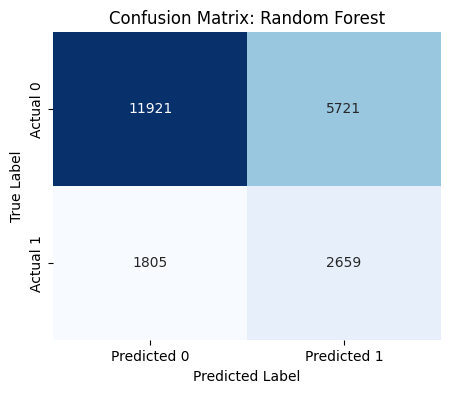

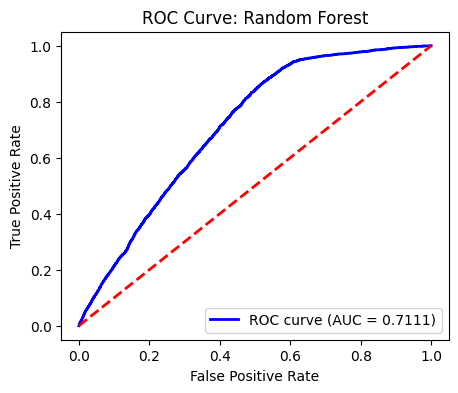


Training XGBoost...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [16:08:13] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


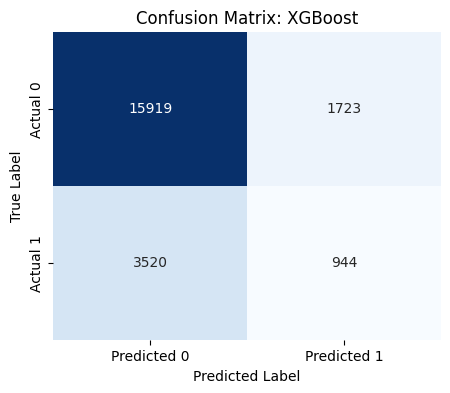

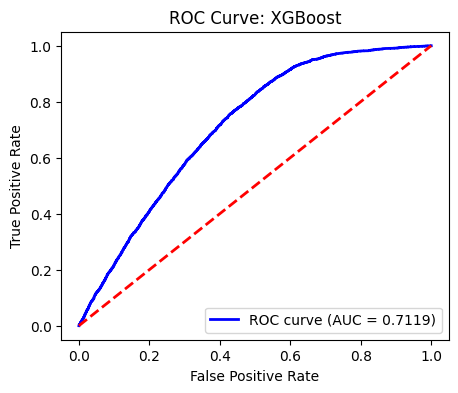


Training LightGBM...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 70565, number of negative: 70565
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.032451 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2002
[LightGBM] [Info] Number of data points in the train set: 141130, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


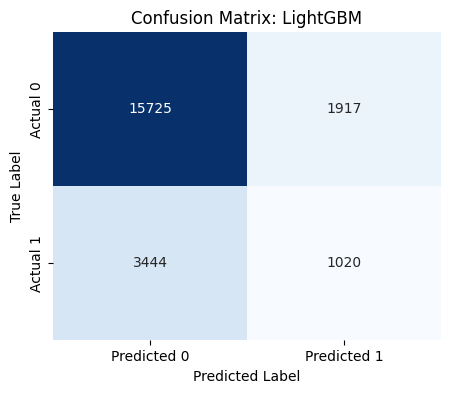

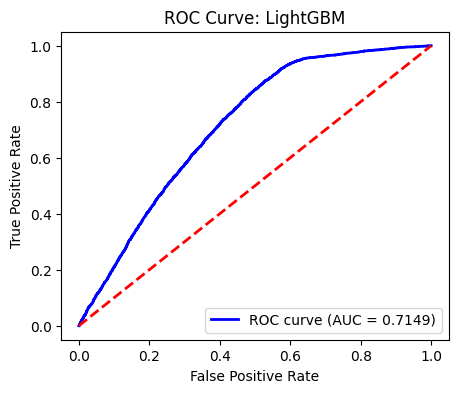


Training CatBoost...


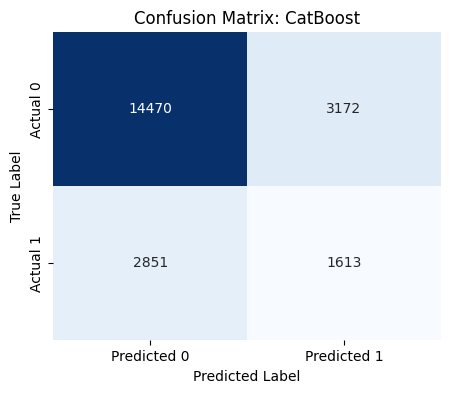

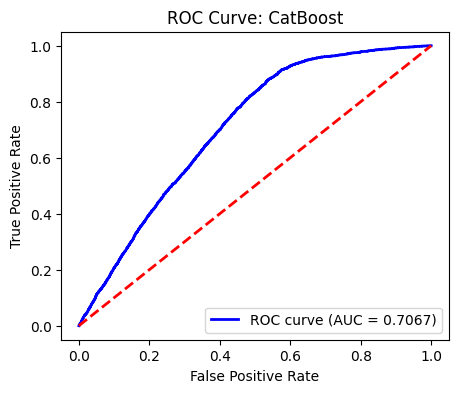


Training Deep Neural Network (DNN)...


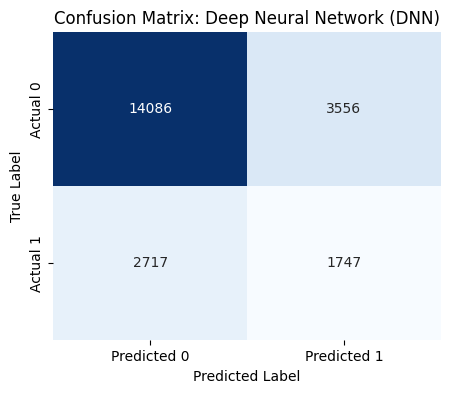

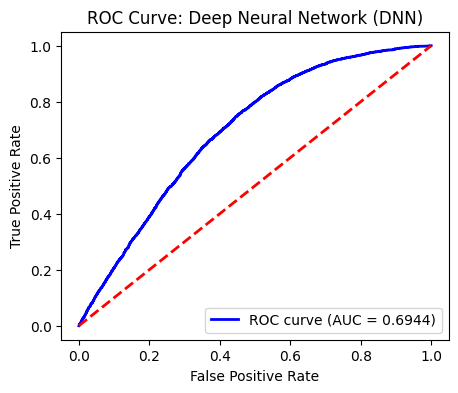


Training HistGradientBoosting...


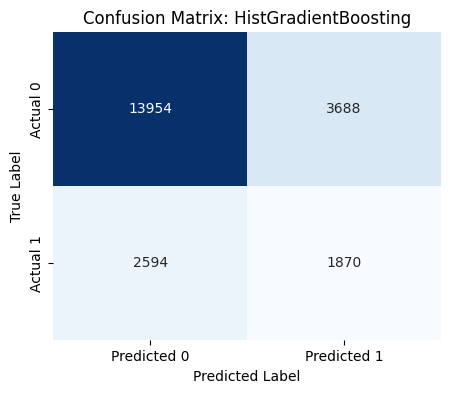

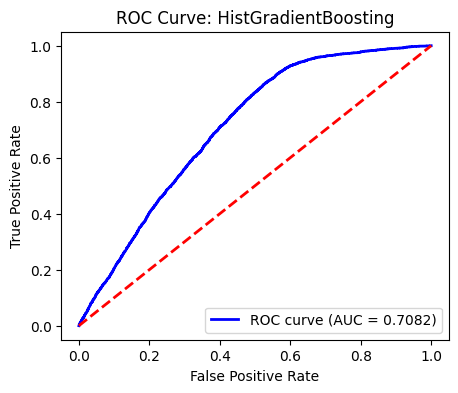


--- Final Model Evaluation Results ---
                       Model  Train Accuracy  Test Accuracy  Precision  \
2                   LightGBM        0.812591       0.757487   0.347293   
1                    XGBoost        0.829335       0.762825   0.353956   
0              Random Forest        0.758740       0.659549   0.317303   
5       HistGradientBoosting        0.781499       0.715824   0.336452   
3                   CatBoost        0.782442       0.727540   0.337095   
4  Deep Neural Network (DNN)        0.774151       0.716231   0.329436   

     Recall  F1 Score   ROC AUC  
2  0.228495  0.275638  0.714929  
1  0.211470  0.264760  0.711883  
0  0.595654  0.414045  0.711136  
5  0.418907  0.373179  0.708232  
3  0.361335  0.348794  0.706714  
4  0.391353  0.357735  0.694421  


In [37]:
# 1. Imports and Setup
# Install CatBoost if not already installed
!pip install catboost
# Import necessary libraries
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import joblib
# Scikit-learn models

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,

    BaggingClassifier,
    HistGradientBoostingClassifier
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.neural_network import MLPClassifier # For ANN and DNN
# Scikit-learn metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve, auc, classification_report
)
# Suppress specific warnings
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')
warnings.filterwarnings('ignore', category=FutureWarning, module='xgboost')
warnings.filterwarnings('ignore', category=UserWarning, module='catboost')

# 2. Model Definition
# Define a dictionary of models to be evaluated.
# ANN is represented by a single hidden layer, DNN by multiple layers.
models = {


    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10, n_jobs=-1),
    'XGBoost': XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss', n_estimators=100, max_depth=5),
    'LightGBM': LGBMClassifier(random_state=42, n_estimators=100, num_leaves=31, learning_rate=0.05, n_jobs=-1),
    'CatBoost': CatBoostClassifier(random_state=42, iterations=100, depth=5, learning_rate=0.05,
                                   loss_function='Logloss', eval_metric='AUC', verbose=0,
                                   early_stopping_rounds=10),

    'Deep Neural Network (DNN)': MLPClassifier(random_state=42, max_iter=1000, hidden_layer_sizes=(100, 50, 25),
                                               early_stopping=True, validation_fraction=0.1),

    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42, max_iter=100, max_depth=5, learning_rate=0.05)

}

# 3. Evaluation Loop
# Create a list to store the results
results = []
# Loop through each model in the dictionary
for name, model in models.items():
    print(f"\nTraining {name}...")
    # Train the model
    model.fit(X_train_res, y_train_res)
    # Make predictions
    y_train_pred = model.predict(X_train_res)
    y_test_pred = model.predict(X_test)
    # Initialize ROC AUC
    roc_auc = np.nan
    # Check for probability or decision function to calculate ROC AUC
    if hasattr(model, "predict_proba"):
        y_test_proba = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_test_proba)
    elif hasattr(model, "decision_function"):
        y_test_proba = model.decision_function(X_test)
        roc_auc = roc_auc_score(y_test, y_test_proba)
    else:
        y_test_proba = np.full(len(y_test), np.nan)
    # Calculate and store performance metrics
    metrics = {
        'Model': name,
        'Train Accuracy': accuracy_score(y_train_res, y_train_pred),
        'Test Accuracy': accuracy_score(y_test, y_test_pred),
        'Precision': precision_score(y_test, y_test_pred, zero_division=0),
        'Recall': recall_score(y_test, y_test_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_test_pred, zero_division=0),
        'ROC AUC': roc_auc
    }
    results.append(metrics)
    # Generate and display the confusion matrix heatmap
    cm = confusion_matrix(y_test, y_test_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Predicted 0', 'Predicted 1'],
                yticklabels=['Actual 0', 'Actual 1'])
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()
    # Plot the ROC curve if a ROC AUC score was calculated
    if not np.isnan(roc_auc):
        fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
        plt.figure(figsize=(5,4))
        plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {metrics["ROC AUC"]:.4f})')
        plt.plot([0,1], [0,1], color='red', lw=2, linestyle='--')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'ROC Curve: {name}')
        plt.legend(loc='lower right')
        plt.show()

# 4. Results Summary
# Convert the list of results to a pandas DataFrame
results_df = pd.DataFrame(results)
# Print the final results table, sorted by ROC AUC
print("\n--- Final Model Evaluation Results ---")
print(results_df.sort_values(by='ROC AUC', ascending=False))

**Hyperparameter tuning using optuna without cross validation**

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.7/404.7 kB 9.1 MB/s eta 0:00:00


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import optuna

# Scikit-learn models
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.neural_network import MLPClassifier

# Scikit-learn metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

# Suppress warnings
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')
warnings.filterwarnings('ignore', category=FutureWarning, module='xgboost')
warnings.filterwarnings('ignore', category=UserWarning, module='catboost')
warnings.filterwarnings('ignore', category=DeprecationWarning)

# 1. Models to Tune
models_for_tuning = {
    'Random Forest': None,
    'XGBoost': None,
    'LightGBM': None,
    'CatBoost': None,
    'Deep Neural Network (DNN)': None,
    'HistGradientBoosting': None,
}

# 2. Optuna Objective Function
def objective(trial, model_name, X_train, X_test, y_train, y_test):
    if model_name == "Random Forest":
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 50, 200),
            "max_depth": trial.suggest_int("max_depth", 3, 20)
        }
        model = RandomForestClassifier(random_state=42, n_jobs=-1, **params)

    elif model_name == "XGBoost":
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 50, 200),
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0)
        }
        model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric="logloss", n_jobs=-1, **params)

    elif model_name == "LightGBM":
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 50, 200),
            "max_depth": trial.suggest_int("max_depth", -1, 15),
            "num_leaves": trial.suggest_int("num_leaves", 15, 63),
            "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0)
        }
        model = LGBMClassifier(random_state=42, n_jobs=-1, **params)

    elif model_name == "CatBoost":
        params = {
            "iterations": trial.suggest_int("iterations", 50, 200),
            "depth": trial.suggest_int("depth", 3, 10),
            "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 10)
        }
        model = CatBoostClassifier(random_state=42, verbose=0, loss_function="Logloss", eval_metric="AUC", **params)

    elif model_name == "Deep Neural Network (DNN)":
        params = {
            "hidden_layer_sizes": (
                trial.suggest_int("layer1", 50, 200),
                trial.suggest_int("layer2", 20, 100),
                trial.suggest_int("layer3", 10, 50)
            ),
            "alpha": trial.suggest_float("alpha", 1e-5, 1e-1, log=True),
            "learning_rate_init": trial.suggest_float("learning_rate_init", 1e-4, 0.1, log=True)
        }
        model = MLPClassifier(random_state=42, max_iter=500, early_stopping=True, validation_fraction=0.1, **params)

    elif model_name == "HistGradientBoosting":
        params = {
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2),
            "max_iter": trial.suggest_int("max_iter", 50, 200)
        }
        model = HistGradientBoostingClassifier(random_state=42, **params)

    else:
        raise ValueError(f"Unsupported model: {model_name}")

    # Train and evaluate
    model.fit(X_train, y_train)
    y_pred_proba = None
    if hasattr(model, "predict_proba"):
        y_pred_proba = model.predict_proba(X_test)
    elif hasattr(model, "decision_function"):
        y_pred_proba = model.decision_function(X_test)

    if y_pred_proba is not None and len(np.unique(y_test)) > 1:
        if len(np.unique(y_test)) == 2:
            return roc_auc_score(y_test, y_pred_proba[:, 1] if y_pred_proba.ndim > 1 else y_pred_proba)
        else:
            return roc_auc_score(y_test, y_pred_proba, multi_class='ovr')
    return 0.0

# 3. Function to Tune and Evaluate
def tune_and_evaluate(model_name, X_train, X_test, y_train, y_test, n_trials=50):
    print(f"\n🔹 Tuning {model_name}...")

    study = optuna.create_study(direction="maximize")
    study.optimize(lambda trial: objective(trial, model_name, X_train, X_test, y_train, y_test),
                   n_trials=n_trials, show_progress_bar=True)
    best_params = study.best_params
    roc_auc = study.best_value
    print(f" Best ROC AUC: {roc_auc:.4f}")
    print("Best Params:", best_params)

    # Instantiate best model
    model_map = {
        "Random Forest": RandomForestClassifier,
        "XGBoost": XGBClassifier,
        "LightGBM": LGBMClassifier,
        "CatBoost": CatBoostClassifier,
        "HistGradientBoosting": HistGradientBoostingClassifier
    }

    if model_name == "Deep Neural Network (DNN)":
        best_model = MLPClassifier(random_state=42, max_iter=500, early_stopping=True,
                                   validation_fraction=0.1, **best_params)
    elif model_name == "CatBoost":
        best_model = CatBoostClassifier(random_state=42, verbose=0, loss_function="Logloss",
                                        eval_metric="AUC", **best_params)
    else:
        best_model = model_map[model_name](random_state=42, **best_params)

    best_model.fit(X_train, y_train)

    # Metrics
    y_train_pred = best_model.predict(X_train)
    y_test_pred = best_model.predict(X_test)

    y_test_proba = None
    if hasattr(best_model, "predict_proba"):
        y_test_proba = best_model.predict_proba(X_test)
    elif hasattr(best_model, "decision_function"):
        y_test_proba = best_model.decision_function(X_test)

    if y_test_proba is not None and len(np.unique(y_test)) > 1:
        if len(np.unique(y_test)) == 2:
            roc_auc = roc_auc_score(y_test, y_test_proba[:, 1] if y_test_proba.ndim > 1 else y_test_proba)
        else:
            roc_auc = roc_auc_score(y_test, y_test_proba, multi_class='ovr')
    else:
        roc_auc = np.nan

    return {
        "Model": model_name,
        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Test Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_test_pred, zero_division=0),
        "ROC AUC": roc_auc
    }

# 4. Run Tuning for All Models
final_results = []
if 'X_train_res' in locals() and 'X_test' in locals():
    for model_name in models_for_tuning.keys():
        try:
            res = tune_and_evaluate(model_name, X_train_res, X_test, y_train_res, y_test, n_trials=50)
            final_results.append(res)
        except Exception as e:
            print(f" Skipping {model_name} due to error: {e}")
else:
    print(" Data (X_train_res, X_test, y_train_res, y_test) not loaded. Please load your dataset.")

# 5. Results Summary
if final_results:
    results_df = pd.DataFrame(final_results)
    print("\n--- Final Model Evaluation Results ---")
    print(results_df.sort_values(by='ROC AUC', ascending=False).round(4))
else:
    print("\nNo results to display. Ensure your data is loaded correctly.")


[I 2025-12-10 21:06:07,475] A new study created in memory with name: no-name-708d333b-c64f-46e3-8b33-98d6ca874b33



🔹 Tuning Random Forest...


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2025-12-10 21:06:45,019] Trial 0 finished with value: 0.7054807884532635 and parameters: {'n_estimators': 187, 'max_depth': 5}. Best is trial 0 with value: 0.7054807884532635.
[I 2025-12-10 21:07:24,294] Trial 1 finished with value: 0.7136156947578257 and parameters: {'n_estimators': 159, 'max_depth': 12}. Best is trial 1 with value: 0.7136156947578257.
[I 2025-12-10 21:07:39,915] Trial 2 finished with value: 0.7120778849674064 and parameters: {'n_estimators': 77, 'max_depth': 18}. Best is trial 1 with value: 0.7136156947578257.
[I 2025-12-10 21:07:57,381] Trial 3 finished with value: 0.7101760360072635 and parameters: {'n_estimators': 142, 'max_depth': 9}. Best is trial 1 with value: 0.7136156947578257.
[I 2025-12-10 21:08:25,315] Trial 4 finished with value: 0.7137178040022609 and parameters: {'n_estimators': 171, 'max_depth': 12}. Best is trial 4 with value: 0.7137178040022609.
[I 2025-12-10 21:08:35,329] Trial 5 finished with value: 0.7131242079121224 and parameters: {'n_estimat

[I 2025-12-10 21:22:25,076] A new study created in memory with name: no-name-e343cf57-499c-4c32-8347-8c867e61903b



🔹 Tuning XGBoost...


... (113 outputs left out)

[I 2025-12-10 23:23:54,727] A new study created in memory with name: no-name-0f8e7d91-d2d2-4e71-9fdc-6409adaf7f74


[I 2025-12-10 23:23:54,707] Trial 49 finished with value: 0.6913911348732394 and parameters: {'layer1': 78, 'layer2': 52, 'layer3': 18, 'alpha': 1.8999288778160553e-05, 'learning_rate_init': 0.0005527072171414029}. Best is trial 46 with value: 0.7055101203384397.
 Best ROC AUC: 0.7055
Best Params: {'layer1': 200, 'layer2': 42, 'layer3': 19, 'alpha': 0.008863212109719435, 'learning_rate_init': 0.0047980240460639865}
 Skipping Deep Neural Network (DNN) due to error: MLPClassifier.__init__() got an unexpected keyword argument 'layer1'

🔹 Tuning HistGradientBoosting...


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2025-12-10 23:23:59,040] Trial 0 finished with value: 0.7055872149448672 and parameters: {'max_depth': 8, 'learning_rate': 0.02731401764232176, 'max_iter': 70}. Best is trial 0 with value: 0.7055872149448672.
[I 2025-12-10 23:24:02,981] Trial 1 finished with value: 0.7027003796942698 and parameters: {'max_depth': 3, 'learning_rate': 0.03441243665059328, 'max_iter': 134}. Best is trial 0 with value: 0.7055872149448672.
[I 2025-12-10 23:24:12,140] Trial 2 finished with value: 0.7130092866018247 and parameters: {'max_depth': 7, 'learning_rate': 0.04166219002771284, 'max_iter': 196}. Best is trial 2 with value: 0.7130092866018247.
[I 2025-12-10 23:24:17,378] Trial 3 finished with value: 0.7122567142335882 and parameters: {'max_depth': 4, 'learning_rate': 0.1872763687754616, 'max_iter': 176}. Best is trial 2 with value: 0.7130092866018247.
[I 2025-12-10 23:24:22,904] Trial 4 finished with value: 0.7151655737936392 and parameters: {'max_depth': 5, 'learning_rate': 0.19038284958990162, 'ma

**Hyperparameter tuning with cross validation**

In [ ]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
import joblib

import optuna
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from tabulate import tabulate

# --------------------------
# 1. Set global seeds
SEED = 42
np.random.seed(SEED)

# --------------------------
# 2. Models for Tuning
models_for_tuning = {

    'Decision Tree': DecisionTreeClassifier,
    'Random Forest': RandomForestClassifier,
    'XGBoost': XGBClassifier,
    'LightGBM': LGBMClassifier,
    'CatBoost': CatBoostClassifier

}

# --------------------------
# 3. Objective function
def objective(trial, model_name, X, y):
    model_class = models_for_tuning[model_name]
    params = {}

    # --- Hyperparameter spaces ---



    if model_name == 'Decision Tree':
        params = {'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
                  'max_depth': trial.suggest_int('max_depth', 3, 20),
                  'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
                  'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
                  'random_state': SEED}

    elif model_name == 'Random Forest':
        params = {'n_estimators': trial.suggest_int('n_estimators', 50, 300),
                  'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
                  'max_depth': trial.suggest_int('max_depth', 3, 20),
                  'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
                  'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
                  'bootstrap': trial.suggest_categorical('bootstrap', [True, False]),
                  'random_state': SEED,
                  'n_jobs': 1}

    elif model_name == 'XGBoost':
        params = {'n_estimators': trial.suggest_int('n_estimators', 50, 300),
                  'max_depth': trial.suggest_int('max_depth', 3, 10),
                  'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
                  'subsample': trial.suggest_float('subsample', 0.5, 1.0),
                  'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
                  'gamma': trial.suggest_float('gamma', 0, 0.5),
                  'use_label_encoder': False,
                  'eval_metric': 'logloss',
                  'random_state': SEED,
                  'n_jobs': 1}

    elif model_name == 'LightGBM':
        params = {'n_estimators': trial.suggest_int('n_estimators', 50, 300),
                  'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
                  'num_leaves': trial.suggest_int('num_leaves', 15, 63),
                  'max_depth': trial.suggest_int('max_depth', -1, 15),
                  'subsample': trial.suggest_float('subsample', 0.5, 1.0),
                  'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
                  'random_state': SEED,
                  'n_jobs': 1}

    elif model_name == 'CatBoost':
        params = {'iterations': trial.suggest_int('iterations', 200, 500),
                  'depth': trial.suggest_int('depth', 4, 10),
                  'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
                  'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10),
                  'verbose': 0,
                  'random_state': SEED}





    # --- 10-Fold CV
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
    scores = []

    for train_idx, val_idx in skf.split(X, y):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]
        try:
            model = model_class(**params)
            model.fit(X_train, y_train)
            if hasattr(model, "predict_proba"):
                y_pred = model.predict_proba(X_val)[:, 1]
            elif hasattr(model, "decision_function"):
                y_pred = model.decision_function(X_val)
            else:
                y_pred = model.predict(X_val)
            if len(np.unique(y_val)) > 1:
                scores.append(roc_auc_score(y_val, y_pred))
        except:
            continue

    return np.mean(scores) if scores else 0.0

# --------------------------
# 4. Tune all models function (Deterministic)
def tune_all_models(X_train, y_train, X_test, y_test, n_trials=50):
    final_results = []
    X_train_np, y_train_np = np.array(X_train), np.array(y_train)
    X_test_np, y_test_np = np.array(X_test), np.array(y_test)

    for model_name in models_for_tuning.keys():
        print(f"\n Tuning {model_name}...")
        try:
            study = optuna.create_study(
                direction='maximize',
                sampler=optuna.samplers.TPESampler(seed=SEED)
            )
            study.optimize(lambda trial: objective(trial, model_name, X_train_np, y_train_np), n_trials=n_trials)
            best_params = study.best_params

            # Add random_state and n_jobs where applicable
            if 'random_state' in models_for_tuning[model_name]().get_params().keys():
                best_params['random_state'] = SEED
            if 'n_jobs' in models_for_tuning[model_name]().get_params().keys():
                best_params['n_jobs'] = 1

            model_class = models_for_tuning[model_name]
            model = model_class(**best_params)
            model.fit(X_train_np, y_train_np)

            y_train_pred = model.predict(X_train_np)
            y_test_pred = model.predict(X_test_np)
            y_test_proba = model.predict_proba(X_test_np)[:, 1] if hasattr(model, "predict_proba") else \
                           (model.decision_function(X_test_np) if hasattr(model, "decision_function") else None)
            roc_auc = roc_auc_score(y_test_np, y_test_proba) if y_test_proba is not None else np.nan

            final_results.append({
                "Model": model_name,
                "Train Accuracy": accuracy_score(y_train_np, y_train_pred),
                "Test Accuracy": accuracy_score(y_test_np, y_test_pred),
                "Precision": precision_score(y_test_np, y_test_pred, zero_division=0),
                "Recall": recall_score(y_test_np, y_test_pred, zero_division=0),
                "F1 Score": f1_score(y_test_np, y_test_pred, zero_division=0),
                "ROC AUC": roc_auc,
                "Best Params": best_params
            })
        except Exception as e:
            print(f" Skipping {model_name} due to error: {e}")

    return pd.DataFrame(final_results)
# -------------------------- # Example: Run Tuning # Make sure X_train_res, y_train_res, X_test, y_test are defined
results_df = tune_all_models(X_train_res, y_train_res, X_test, y_test, n_trials=50)


# Format results table
cols_order = ["Model", "Train Accuracy", "Test Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC", "Best Params"]
results_df = results_df[cols_order]
for col in ["Train Accuracy", "Test Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]:
    results_df[col] = results_df[col].round(4)

print("\n--- Hyperparameter Tuning Results ---")
print(tabulate(results_df, headers='keys', tablefmt='fancy_grid', showindex=True))


[I 2025-12-06 06:46:39,001] A new study created in memory with name: no-name-93131040-b9bb-4148-9a25-7ea543fc0126



 Tuning Decision Tree...


[I 2025-12-06 06:47:12,051] Trial 0 finished with value: 0.8552074798201363 and parameters: {'criterion': 'entropy', 'max_depth': 16, 'min_samples_split': 7, 'min_samples_leaf': 1}. Best is trial 0 with value: 0.8552074798201363.
[I 2025-12-06 06:47:28,718] Trial 1 finished with value: 0.8575739345263399 and parameters: {'criterion': 'gini', 'max_depth': 18, 'min_samples_split': 7, 'min_samples_leaf': 4}. Best is trial 1 with value: 0.8575739345263399.
[I 2025-12-06 06:47:45,493] Trial 2 finished with value: 0.8523037606474265 and parameters: {'criterion': 'entropy', 'max_depth': 17, 'min_samples_split': 3, 'min_samples_leaf': 1}. Best is trial 1 with value: 0.8575739345263399.
[I 2025-12-06 06:47:59,628] Trial 3 finished with value: 0.8437720477520753 and parameters: {'criterion': 'entropy', 'max_depth': 12, 'min_samples_split': 5, 'min_samples_leaf': 2}. Best is trial 1 with value: 0.8575739345263399.
[I 2025-12-06 06:48:10,619] Trial 4 finished with value: 0.808079062714784 and para


 Tuning Random Forest...


[I 2025-12-06 07:04:28,391] Trial 0 finished with value: 0.8731643120145417 and parameters: {'n_estimators': 144, 'criterion': 'gini', 'max_depth': 13, 'min_samples_split': 3, 'min_samples_leaf': 1, 'bootstrap': False}. Best is trial 0 with value: 0.8731643120145417.
[I 2025-12-06 07:14:07,880] Trial 1 finished with value: 0.9073020303251432 and parameters: {'n_estimators': 200, 'criterion': 'gini', 'max_depth': 20, 'min_samples_split': 9, 'min_samples_leaf': 2, 'bootstrap': False}. Best is trial 1 with value: 0.9073020303251432.
[I 2025-12-06 07:17:43,288] Trial 2 finished with value: 0.8370769215413718 and parameters: {'n_estimators': 126, 'criterion': 'gini', 'max_depth': 8, 'min_samples_split': 7, 'min_samples_leaf': 1, 'bootstrap': False}. Best is trial 1 with value: 0.9073020303251432.
[I 2025-12-06 07:22:06,530] Trial 3 finished with value: 0.8653816372801069 and parameters: {'n_estimators': 164, 'criterion': 'gini', 'max_depth': 12, 'min_samples_split': 7, 'min_samples_leaf': 1


 Tuning XGBoost...


... (102 outputs left out)

[I 2025-12-06 13:38:08,540] A new study created in memory with name: no-name-17a7164e-9d87-4d31-aee7-a3f214d6ce64



 Tuning CatBoost...


[I 2025-12-06 13:44:09,062] Trial 0 finished with value: 0.921720039156374 and parameters: {'iterations': 312, 'depth': 10, 'learning_rate': 0.06504856968981275, 'l2_leaf_reg': 6.387926357773329}. Best is trial 0 with value: 0.921720039156374.
[I 2025-12-06 13:45:42,896] Trial 1 finished with value: 0.8039576252186199 and parameters: {'iterations': 246, 'depth': 5, 'learning_rate': 0.0013927723945289009, 'l2_leaf_reg': 8.795585311974417}. Best is trial 0 with value: 0.921720039156374.
[I 2025-12-06 13:49:12,379] Trial 2 finished with value: 0.8424937581073711 and parameters: {'iterations': 380, 'depth': 8, 'learning_rate': 0.001124579825911934, 'l2_leaf_reg': 9.72918866945795}. Best is trial 0 with value: 0.921720039156374.
[I 2025-12-06 13:51:54,164] Trial 3 finished with value: 0.84275161749788 and parameters: {'iterations': 450, 'depth': 5, 'learning_rate': 0.002820996133514492, 'l2_leaf_reg': 2.650640588680904}. Best is trial 0 with value: 0.921720039156374.
[I 2025-12-06 13:54:13,

0:	learn: 0.5718850	total: 253ms	remaining: 1m 24s
1:	learn: 0.5345053	total: 544ms	remaining: 1m 30s
2:	learn: 0.5008446	total: 750ms	remaining: 1m 22s
3:	learn: 0.4835350	total: 911ms	remaining: 1m 14s
4:	learn: 0.4725429	total: 1.05s	remaining: 1m 8s
5:	learn: 0.4659204	total: 1.17s	remaining: 1m 3s
6:	learn: 0.4597381	total: 1.34s	remaining: 1m 2s
7:	learn: 0.4519852	total: 1.45s	remaining: 59.1s
8:	learn: 0.4458054	total: 1.59s	remaining: 57.1s
9:	learn: 0.4429193	total: 1.7s	remaining: 54.9s
10:	learn: 0.4327952	total: 1.83s	remaining: 53.5s
11:	learn: 0.4291129	total: 1.95s	remaining: 52.3s
12:	learn: 0.4245561	total: 2.1s	remaining: 51.7s
13:	learn: 0.4226338	total: 2.22s	remaining: 50.6s
14:	learn: 0.4214441	total: 2.39s	remaining: 50.8s
15:	learn: 0.4192423	total: 2.51s	remaining: 49.7s
16:	learn: 0.4172328	total: 2.65s	remaining: 49.3s
17:	learn: 0.4147411	total: 2.77s	remaining: 48.4s
18:	learn: 0.4117377	total: 2.91s	remaining: 48.1s
19:	learn: 0.4105032	total: 3.03s	remai

In [ ]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
import joblib

import optuna
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

from sklearn.ensemble import (

    HistGradientBoostingClassifier

)

from tabulate import tabulate

# --------------------------
# 1. Set global seeds
SEED = 42
np.random.seed(SEED)

# --------------------------
# 2. Models for Tuning
models_for_tuning = {

    'HistGradientBoosting': HistGradientBoostingClassifier

}

# --------------------------
# 3. Objective function
def objective(trial, model_name, X, y):
    model_class = models_for_tuning[model_name]
    params = {}

    # --- Hyperparameter spaces ---


    if model_name == 'HistGradientBoosting':
        params = {
            'max_iter': trial.suggest_int('max_iter', 100, 300),
            'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 20, 50),
            'l2_regularization': trial.suggest_float('l2_regularization', 0.0, 1.0),
            'random_state': SEED
        }



    # --- 10-Fold CV ---
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
    scores = []

    for train_idx, val_idx in skf.split(X, y):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        try:
            model = model_class(**params)
            model.fit(X_train, y_train)

            if hasattr(model, "predict_proba"):
                y_pred = model.predict_proba(X_val)[:, 1]
            elif hasattr(model, "decision_function"):
                y_pred = model.decision_function(X_val)
            else:
                y_pred = model.predict(X_val)

            if len(np.unique(y_val)) > 1:
                scores.append(roc_auc_score(y_val, y_pred))
        except:
            continue

    return np.mean(scores) if scores else 0.0


# --------------------------
# 4. Tune all models function
def tune_all_models(X_train, y_train, X_test, y_test, n_trials=50):
    final_results = []

    X_train_np, y_train_np = np.array(X_train), np.array(y_train)
    X_test_np, y_test_np = np.array(X_test), np.array(y_test)

    for model_name in models_for_tuning.keys():
        print(f"\n Tuning {model_name}...")

        try:
            study = optuna.create_study(
                direction='maximize',
                sampler=optuna.samplers.TPESampler(seed=SEED)
            )

            study.optimize(
                lambda trial: objective(trial, model_name, X_train_np, y_train_np),
                n_trials=n_trials
            )

            best_params = study.best_params

            # Add random_state automatically
            if 'random_state' in models_for_tuning[model_name]().get_params().keys():
                best_params['random_state'] = SEED

            model_class = models_for_tuning[model_name]
            model = model_class(**best_params)
            model.fit(X_train_np, y_train_np)

            y_train_pred = model.predict(X_train_np)
            y_test_pred = model.predict(X_test_np)

            # Probabilities for AUC
            if hasattr(model, "predict_proba"):
                y_test_proba = model.predict_proba(X_test_np)[:, 1]
            elif hasattr(model, "decision_function"):
                y_test_proba = model.decision_function(X_test_np)
            else:
                y_test_proba = None

            roc_auc = roc_auc_score(y_test_np, y_test_proba) if y_test_proba is not None else np.nan

            final_results.append({
                "Model": model_name,
                "Train Accuracy": accuracy_score(y_train_np, y_train_pred),
                "Test Accuracy": accuracy_score(y_test_np, y_test_pred),
                "Precision": precision_score(y_test_np, y_test_pred, zero_division=0),
                "Recall": recall_score(y_test_np, y_test_pred, zero_division=0),
                "F1 Score": f1_score(y_test_np, y_test_pred, zero_division=0),
                "ROC AUC": roc_auc,
                "Best Params": best_params
            })

        except Exception as e:
            print(f" Skipping {model_name} due to error: {e}")

    return pd.DataFrame(final_results)


# --------------------------
# 5. Run Tuning
results_df = tune_all_models(X_train_res, y_train_res, X_test, y_test, n_trials=50)

# Order columns
cols_order = [
    "Model", "Train Accuracy", "Test Accuracy",
    "Precision", "Recall", "F1 Score", "ROC AUC", "Best Params"
]

results_df = results_df[cols_order]

# Round numeric columns
for col in ["Train Accuracy", "Test Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]:
    results_df[col] = results_df[col].round(4)

print("\n--- Hyperparameter Tuning Results ---")
print(tabulate(results_df, headers='keys', tablefmt='fancy_grid', showindex=True))


[I 2025-12-10 23:37:20,219] A new study created in memory with name: no-name-b09c222c-cd71-41c3-8540-c4e5cf050c04



 Tuning HistGradientBoosting...


[I 2025-12-10 23:38:25,000] Trial 0 finished with value: 0.9124655250957783 and parameters: {'max_iter': 175, 'learning_rate': 0.22648248189516848, 'max_depth': 8, 'min_samples_leaf': 38, 'l2_regularization': 0.15601864044243652}. Best is trial 0 with value: 0.9124655250957783.
[I 2025-12-10 23:39:28,100] Trial 1 finished with value: 0.810836869287888 and parameters: {'max_iter': 131, 'learning_rate': 0.0013927723945289009, 'max_depth': 9, 'min_samples_leaf': 38, 'l2_regularization': 0.7080725777960455}. Best is trial 0 with value: 0.9124655250957783.
[I 2025-12-10 23:40:10,614] Trial 2 finished with value: 0.9098513346697141 and parameters: {'max_iter': 104, 'learning_rate': 0.2526878207508456, 'max_depth': 9, 'min_samples_leaf': 26, 'l2_regularization': 0.18182496720710062}. Best is trial 0 with value: 0.9124655250957783.
[I 2025-12-10 23:41:15,711] Trial 3 finished with value: 0.8300111878509847 and parameters: {'max_iter': 136, 'learning_rate': 0.005670807781371429, 'max_depth': 7,


--- Hyperparameter Tuning Results ---
╒════╤══════════════════════╤══════════════════╤═════════════════╤═════════════╤══════════╤════════════╤═══════════╤══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════╕
│    │ Model                │   Train Accuracy │   Test Accuracy │   Precision │   Recall │   F1 Score │   ROC AUC │ Best Params                                                                                                                                                  │
╞════╪══════════════════════╪══════════════════╪═════════════════╪═════════════╪══════════╪════════════╪═══════════╪══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════╡
│  0 │ HistGradientBoosting │           0.8581 │          0.7724 │      0.3846 │   0.2121 │     0.2735 │     0.714 │ {'max_iter': 284

**Bagging + Boosting**


Training Hybrid Bagging + Boosting Ensemble
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 17855, number of negative: 70565
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.024501 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1209
[LightGBM] [Info] Number of data points in the train set: 88420, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.201934 -> initscore=-1.374251
[LightGBM] [Info] Start training from score -1.374251

Train Acc: 0.8478
Test Acc: 0.7969
Precision: 0.3452
Recall: 0.0065
F1 Score: 0.0128
ROC AUC: 0.6257

Classification Report (Test Data):
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     17642
           1       0.35      0.01      0.01      4464

    accuracy                           0.80     22106
   macro avg       0.57  

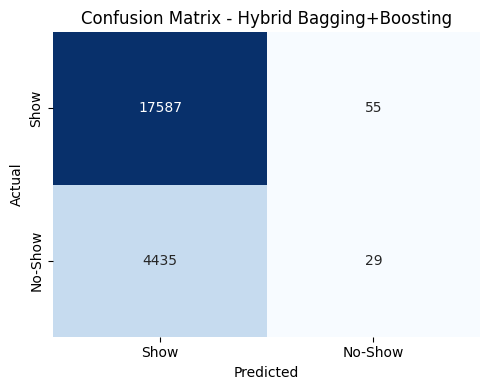

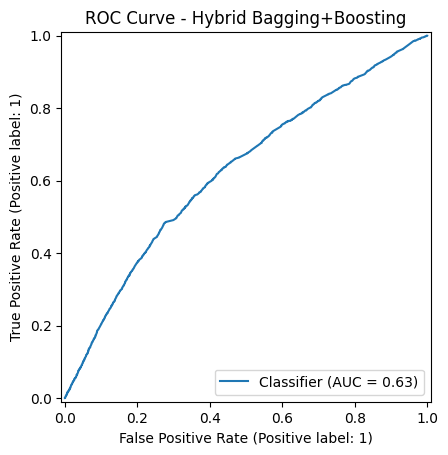


=== Hybrid Bagging + Boosting Ensemble Results ===
                         Train Accuracy  Test Accuracy  Precision    Recall  \
Model                                                                         
Hybrid_Bagging+Boosting        0.847806       0.796888   0.345238  0.006496   

                         F1 Score   ROC AUC  
Model                                        
Hybrid_Bagging+Boosting  0.012753  0.625745  


In [ ]:
# =========================================
# 1. Import Libraries
# =========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import BaggingClassifier, VotingClassifier, GradientBoostingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    precision_score, recall_score,
    classification_report, confusion_matrix, RocCurveDisplay
)


# =========================================
# 2. Define Base Models
# =========================================
gb = GradientBoostingClassifier(
    n_estimators=200, learning_rate=0.15, max_depth=7, random_state=42
)

lgb = LGBMClassifier(
    n_estimators=102, learning_rate=0.2916, num_leaves=51,
    max_depth=14, subsample=0.5921,
    random_state=42, n_jobs=1
)

cat = CatBoostClassifier(
    iterations=219, depth=10, learning_rate=0.2466,
    l2_leaf_reg=8.2756, verbose=0, random_state=42
)

xgb = XGBClassifier(
    n_estimators=246, max_depth=8, learning_rate=0.1215,
    subsample=0.6695, colsample_bytree=0.899,
    gamma=0.3527, random_state=42,
    use_label_encoder=False, eval_metric='logloss', n_jobs=1
)

rf = RandomForestClassifier(
    n_estimators=229, max_depth=20, random_state=42, n_jobs=1
)


# =========================================
# 3. Define Bagging Wrapper
# =========================================
bagged_gb = BaggingClassifier(
    estimator=gb,
    n_estimators=10,
    max_samples=0.8,
    max_features=1.0,
    bootstrap=True,
    n_jobs=1,
    random_state=42
)


# =========================================
# 4. Define Hybrid Voting Ensemble
# =========================================
hybrid_voting = VotingClassifier(
    estimators=[
        ("bagged_gb", bagged_gb),
        ("cat", cat),
        ("lgb", lgb),
        ("xgb", xgb),
        ("rf", rf)
    ],
    voting="soft",
    n_jobs=1
)


# =========================================
# 5. Train & Evaluate
# =========================================
print("\n" + "="*50)
print("Training Hybrid Bagging + Boosting Ensemble")
print("="*50)

hybrid_voting.fit(X_train, y_train)

# Predictions
y_train_pred = hybrid_voting.predict(X_train)
y_test_pred = hybrid_voting.predict(X_test)
y_test_proba = hybrid_voting.predict_proba(X_test)[:, 1]

# Metrics
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
roc_auc = roc_auc_score(y_test, y_test_proba)

# Print metrics
print(f"\nTrain Acc: {train_acc:.4f}")
print(f"Test Acc: {test_acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

# Classification Report
print("\nClassification Report (Test Data):")
print(classification_report(y_test, y_test_pred))


# =========================================
# 6. Confusion Matrix
# =========================================
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Show', 'No-Show'],
            yticklabels=['Show', 'No-Show'])
plt.title("Confusion Matrix - Hybrid Bagging+Boosting")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# =========================================
# 7. ROC Curve
# =========================================
RocCurveDisplay.from_predictions(y_test, y_test_proba)
plt.title("ROC Curve - Hybrid Bagging+Boosting")
plt.show()


# =========================================
# 8. Results DataFrame
# =========================================
results = [{
    "Model": "Hybrid_Bagging+Boosting",
    "Train Accuracy": train_acc,
    "Test Accuracy": test_acc,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC AUC": roc_auc
}]

results_df = pd.DataFrame(results).set_index("Model")

print("\n" + "="*60)
print("=== Hybrid Bagging + Boosting Ensemble Results ===")
print("="*60)
print(results_df)


**voting**


Training Ensemble: GB + CatBoost + LGBM
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 17855, number of negative: 70565
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018101 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1209
[LightGBM] [Info] Number of data points in the train set: 88420, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.201934 -> initscore=-1.374251
[LightGBM] [Info] Start training from score -1.374251
              precision    recall  f1-score   support

           0       0.80      0.98      0.88     17642
           1       0.29      0.03      0.06      4464

    accuracy                           0.79     22106
   macro avg       0.54      0.51      0.47     22106
weighted avg       0.70      0.79      0.71     2

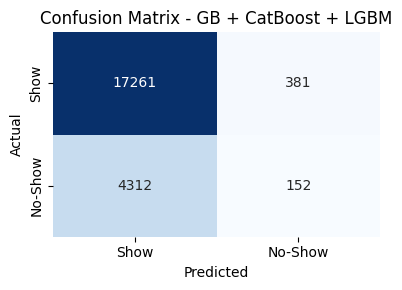


Training Ensemble: GB + CatBoost + RF
              precision    recall  f1-score   support

           0       0.80      0.98      0.88     17642
           1       0.28      0.04      0.07      4464

    accuracy                           0.79     22106
   macro avg       0.54      0.51      0.47     22106
weighted avg       0.69      0.79      0.71     22106



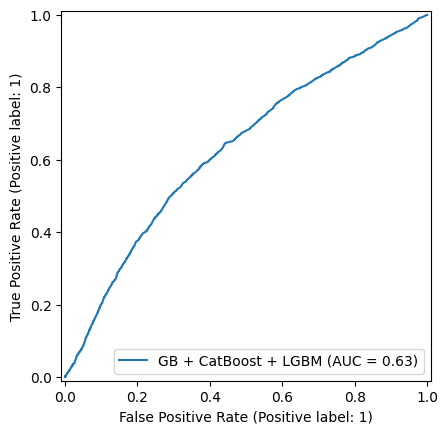

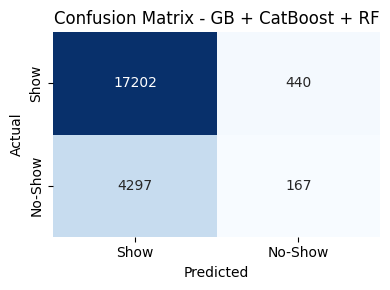


Training Ensemble: GB + CatBoost + LGBM + XGB
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 17855, number of negative: 70565
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017960 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1209
[LightGBM] [Info] Number of data points in the train set: 88420, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.201934 -> initscore=-1.374251
[LightGBM] [Info] Start training from score -1.374251


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [13:12:47] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

           0       0.80      0.99      0.88     17642
           1       0.29      0.02      0.03      4464

    accuracy                           0.79     22106
   macro avg       0.55      0.50      0.46     22106
weighted avg       0.70      0.79      0.71     22106



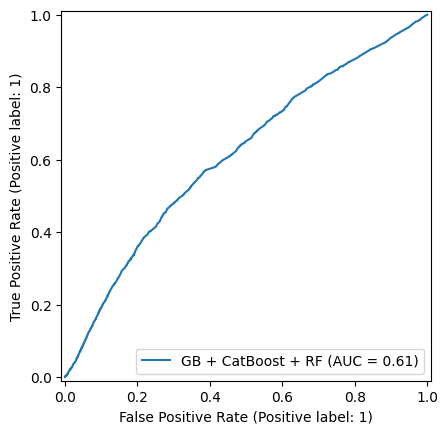

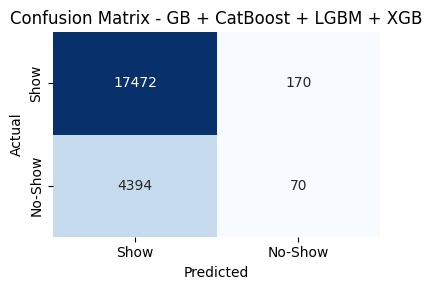


Training Ensemble: GB + CatBoost + RF + LR
              precision    recall  f1-score   support

           0       0.80      0.99      0.88     17642
           1       0.28      0.02      0.03      4464

    accuracy                           0.79     22106
   macro avg       0.54      0.50      0.46     22106
weighted avg       0.70      0.79      0.71     22106



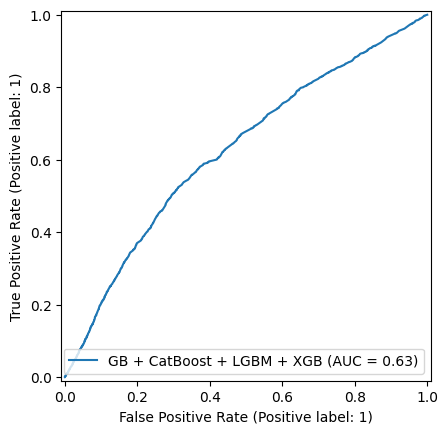

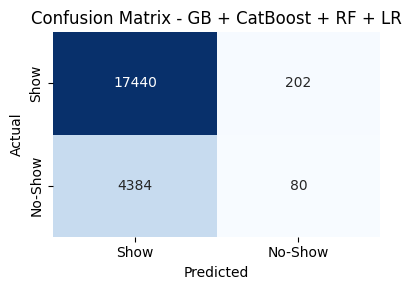


--- Final Ensemble Performance Summary ---
                            Train Accuracy  Test Accuracy  Precision  \
Model                                                                  
GB + CatBoost + LGBM + XGB        0.839188       0.793540   0.291667   
GB + CatBoost + RF + LR           0.837028       0.792545   0.283688   
GB + CatBoost + LGBM              0.836609       0.787705   0.285178   
GB + CatBoost + RF                0.856899       0.785714   0.275124   

                              Recall  F1 Score   ROC AUC  Overfitting Gap  
Model                                                                      
GB + CatBoost + LGBM + XGB  0.015681  0.029762  0.625158         0.045648  
GB + CatBoost + RF + LR     0.017921  0.033713  0.626606         0.044483  
GB + CatBoost + LGBM        0.034050  0.060837  0.628733         0.048905  
GB + CatBoost + RF          0.037410  0.065865  0.612513         0.071185  


/tmp/ipython-input-2656145114.py:161: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")


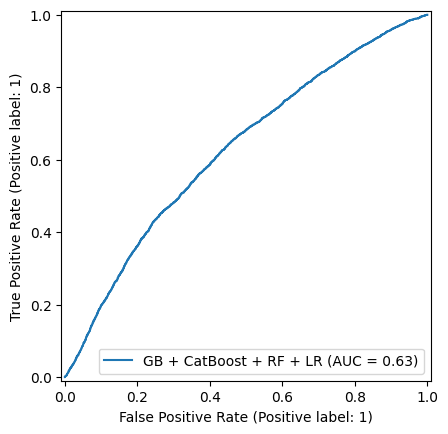

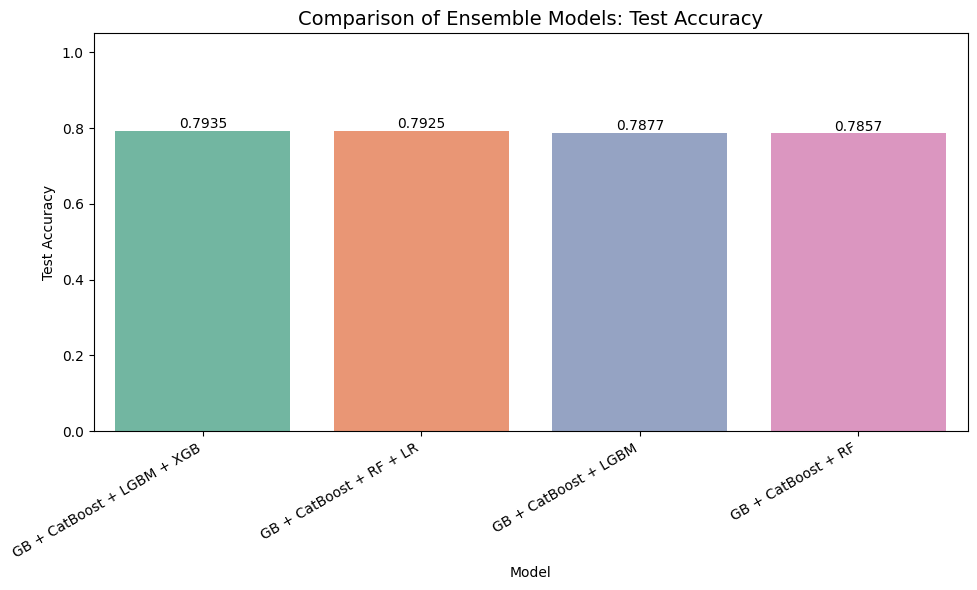

/tmp/ipython-input-2656145114.py:161: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")


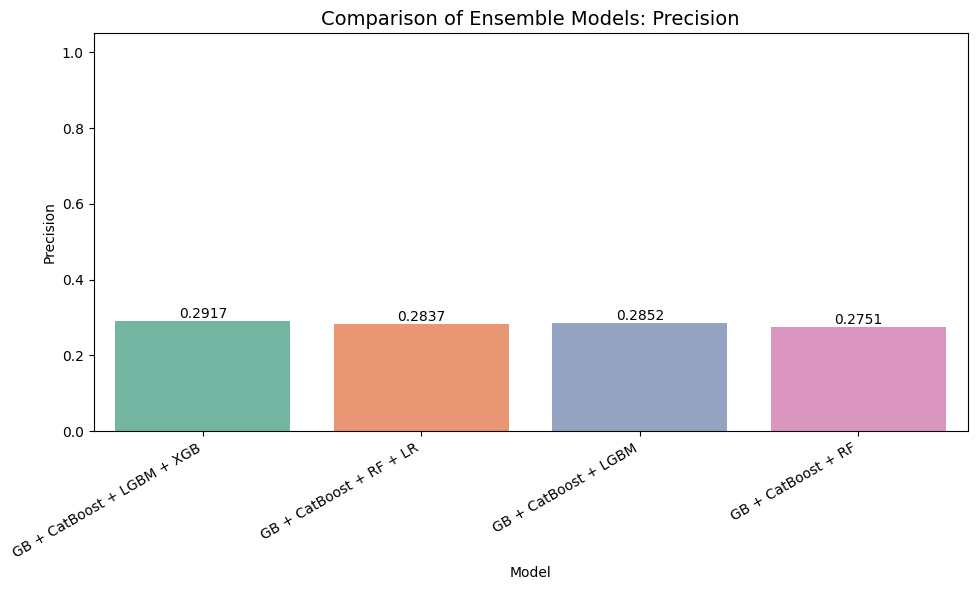

/tmp/ipython-input-2656145114.py:161: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")


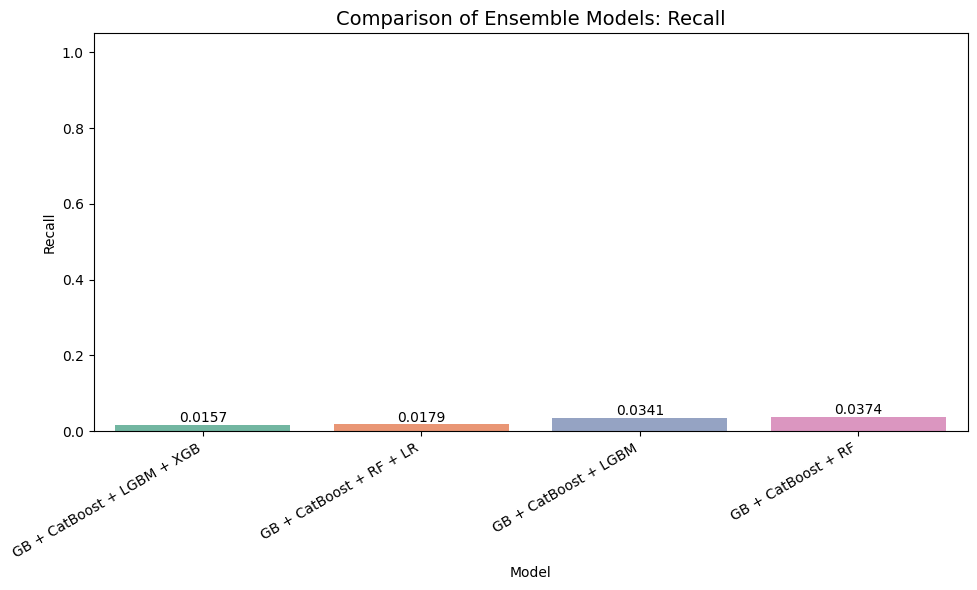

/tmp/ipython-input-2656145114.py:161: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")


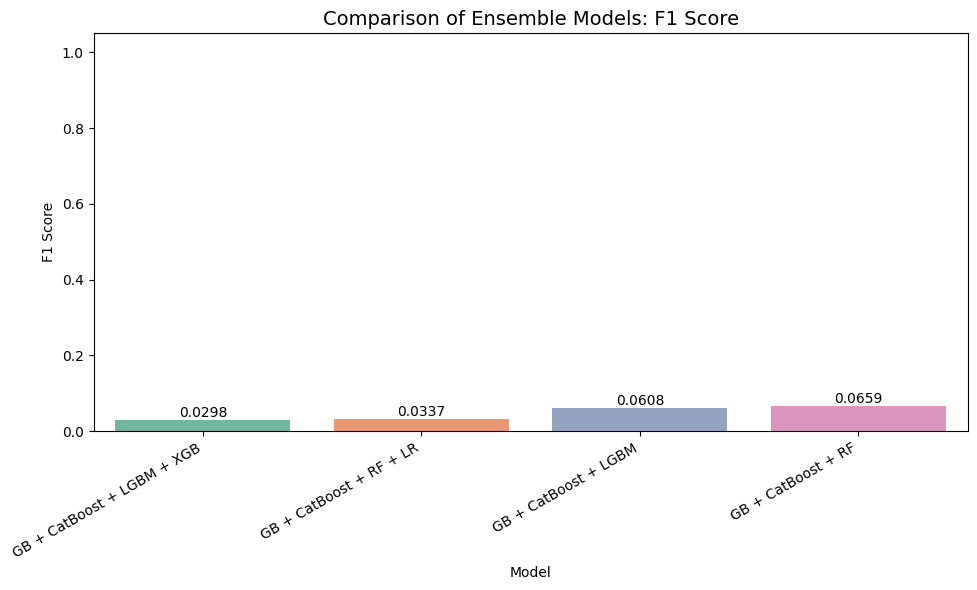

/tmp/ipython-input-2656145114.py:161: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")


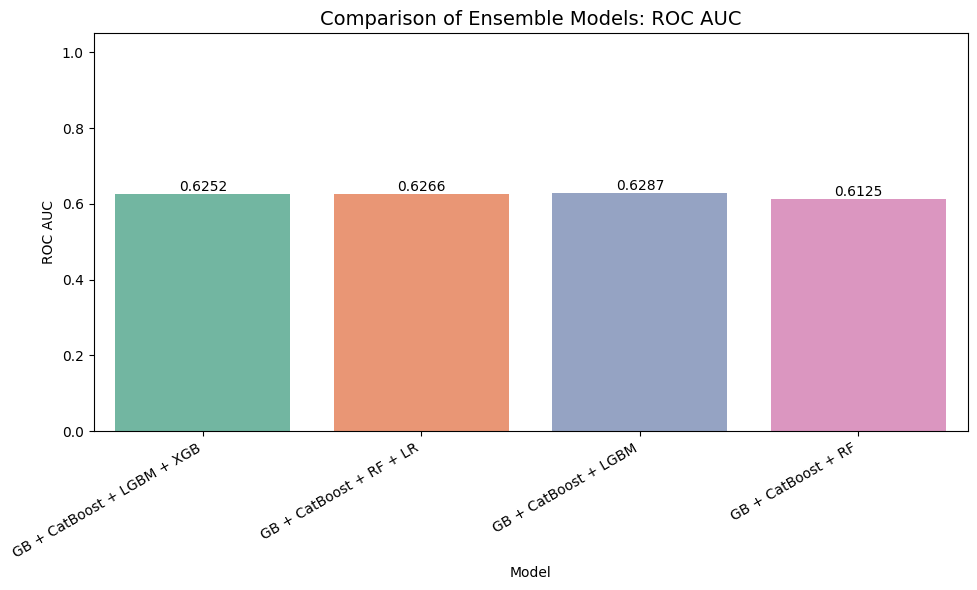

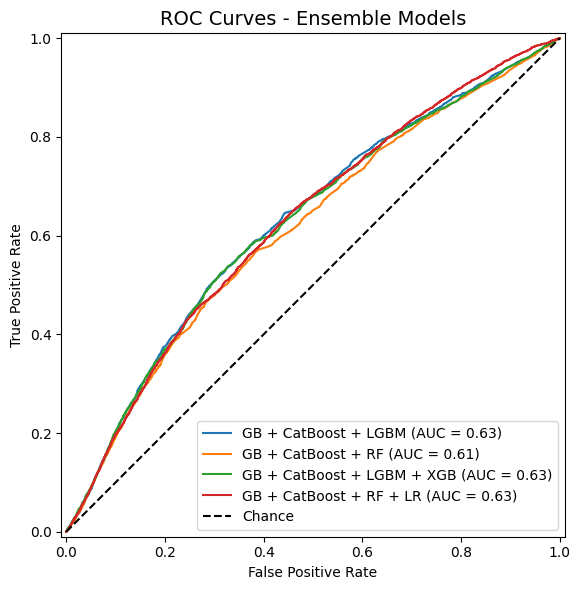

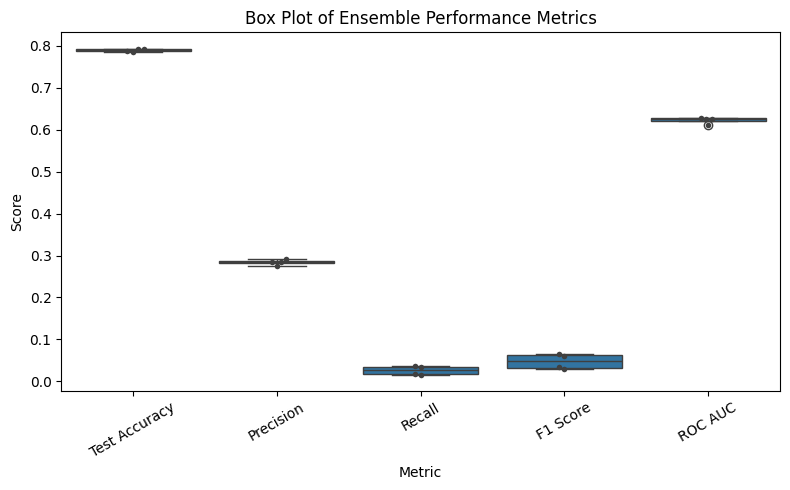

In [ ]:
# =========================================
# 1. Import Libraries
# =========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import VotingClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    classification_report, confusion_matrix, RocCurveDisplay,
    precision_score, recall_score
)


# =========================================
# 2. Define Base Models
# =========================================
gb = GradientBoostingClassifier(
    n_estimators=199, learning_rate=0.1417, max_depth=7,
    subsample=0.8969, min_samples_split=3, random_state=42
)

lgb = LGBMClassifier(
    n_estimators=102, learning_rate=0.2916, num_leaves=51,
    max_depth=14, subsample=0.5921, colsample_bytree=0.9990,
    random_state=42, n_jobs=1
)

cat = CatBoostClassifier(
    iterations=219, depth=10, learning_rate=0.2466,
    l2_leaf_reg=8.2756, verbose=0, random_state=42
)

xgb = XGBClassifier(
    n_estimators=246, max_depth=8, learning_rate=0.1215,
    subsample=0.6695, colsample_bytree=0.8990, gamma=0.3527,
    random_state=42, n_jobs=1, use_label_encoder=False,
    eval_metric='logloss'
)

rf = RandomForestClassifier(
    n_estimators=229, criterion='gini', max_depth=20,
    min_samples_split=6, min_samples_leaf=2,
    bootstrap=False, random_state=42, n_jobs=1
)

lr = LogisticRegression(max_iter=2000, random_state=42)
svm = SVC(probability=True, random_state=42)


# =========================================
# 3. Define Ensemble Combinations
# =========================================
ensemble_models = {
    "GB + CatBoost + LGBM": VotingClassifier(
        estimators=[("gb", gb), ("cat", cat), ("lgb", lgb)], voting="soft"
    ),
    "GB + CatBoost + RF": VotingClassifier(
        estimators=[("gb", gb), ("cat", cat), ("rf", rf)], voting="soft"
    ),
    "GB + CatBoost + LGBM + XGB": VotingClassifier(
        estimators=[("gb", gb), ("cat", cat), ("lgb", lgb), ("xgb", xgb)], voting="soft"
    ),
    "GB + CatBoost + RF + LR": VotingClassifier(
        estimators=[("gb", gb), ("cat", cat), ("rf", rf), ("lr", lr)], voting="soft"
    ),
}


# =========================================
# 4. Train, Evaluate & Collect Results
# =========================================
all_results = []
roc_plot_data = {}

for name, model in ensemble_models.items():
    print(f"\n{'='*40}")
    print(f"Training Ensemble: {name}")
    print(f"{'='*40}")

    # --- Train the model
    model.fit(X_train, y_train)

    # --- Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    y_test_proba = model.predict_proba(X_test)[:, 1]

    # --- Metrics
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred)
    recall = recall_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred)
    roc_auc = roc_auc_score(y_test, y_test_proba)

    # --- Store results
    current_results = {
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": roc_auc
    }
    all_results.append(current_results)

    # --- Classification Report
    print(classification_report(y_test, y_test_pred))

    # --- Confusion Matrix
    cm = confusion_matrix(y_test, y_test_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Show', 'No-Show'],
                yticklabels=['Show', 'No-Show'])
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    # --- ROC Data for Combined Plot
    roc_plot_data[name] = RocCurveDisplay.from_predictions(
        y_test, y_test_proba, name=name
    )


# =========================================
# 5. Results DataFrame
# =========================================
results_df = pd.DataFrame(all_results)
results_df['Overfitting Gap'] = results_df['Train Accuracy'] - results_df['Test Accuracy']
results_df = results_df.set_index("Model").sort_values(by="Test Accuracy", ascending=False)

print("\n" + "="*60)
print("--- Final Ensemble Performance Summary ---")
print("="*60)
print(results_df)


# =========================================
# 6. Visualization Functions
# =========================================
def plot_metric_comparison(results_dataframe):
    """Bar plots for each performance metric."""
    metrics_to_plot = ["Test Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]

    for metric in metrics_to_plot:
        plt.figure(figsize=(10, 6))
        sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")

        ax = plt.gca()
        for p in ax.patches:
            ax.annotate(f'{p.get_height():.4f}',
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', fontsize=10, color='black',
                        xytext=(0, 5), textcoords='offset points')

        plt.title(f"Comparison of Ensemble Models: {metric}", fontsize=14)
        plt.ylabel(metric)
        plt.xlabel("Model")
        plt.xticks(rotation=30, ha="right")
        plt.ylim(0, 1.05)
        plt.tight_layout()
        plt.show()


def plot_comparative_roc(roc_data_dict):
    """Combined ROC curve plot."""
    plt.figure(figsize=(8, 6))

    for name, display in roc_data_dict.items():
        display.plot(ax=plt.gca())

    plt.plot([0, 1], [0, 1], 'k--', label="Chance")
    plt.title("ROC Curves - Ensemble Models", fontsize=14)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.tight_layout()
    plt.show()


# =========================================
# 7. Generate Plots
# =========================================
plot_metric_comparison(results_df)
plot_comparative_roc(roc_plot_data)


# =========================================
# 8. Box Plot for Metric Distribution
# =========================================
melted_results = results_df.reset_index().melt(
    id_vars="Model",
    value_vars=["Test Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"],
    var_name="Metric", value_name="Score"
)

plt.figure(figsize=(8, 5))
sns.boxplot(x="Metric", y="Score", data=melted_results)
sns.swarmplot(x="Metric", y="Score", data=melted_results, color=".25", size=4)
plt.title("Box Plot of Ensemble Performance Metrics")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**stacking**


Training Stacking Ensemble: Stack: GB + LGBM + CatBoost
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 17855, number of negative: 70565
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.022645 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1209
[LightGBM] [Info] Number of data points in the train set: 88420, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.201934 -> initscore=-1.374251
[LightGBM] [Info] Start training from score -1.374251
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 11903, number of negative: 47043
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012080 seconds.
You can set `force_row_wise=true` to remove the ov

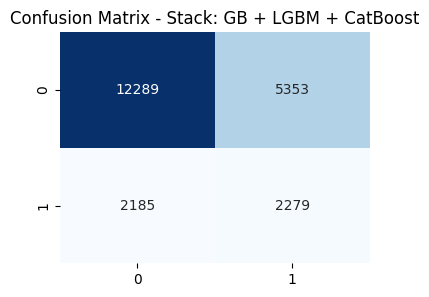


Training Stacking Ensemble: Stack: GB + LGBM + XGB
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 17855, number of negative: 70565
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018292 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1209
[LightGBM] [Info] Number of data points in the train set: 88420, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.201934 -> initscore=-1.374251
[LightGBM] [Info] Start training from score -1.374251
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 11903, number of negative: 47043
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012203 seconds.
You can set `force_row_wise=true` to remove the overhea

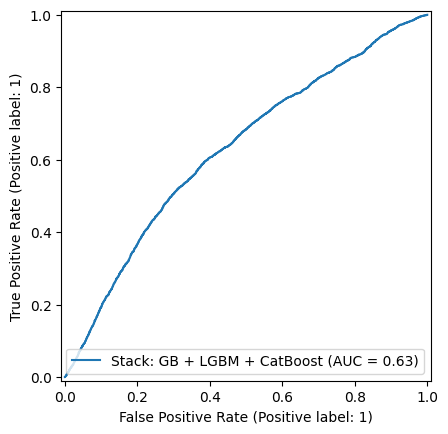

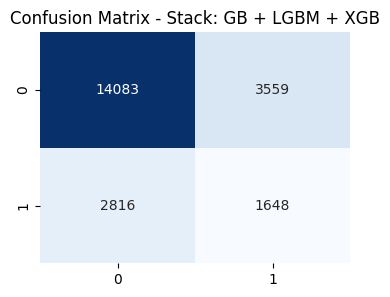


Training Stacking Ensemble: Stack: CatBoost + RF + GB
              precision    recall  f1-score   support

           0       0.85      0.67      0.75     17642
           1       0.28      0.52      0.37      4464

    accuracy                           0.64     22106
   macro avg       0.57      0.59      0.56     22106
weighted avg       0.73      0.64      0.67     22106



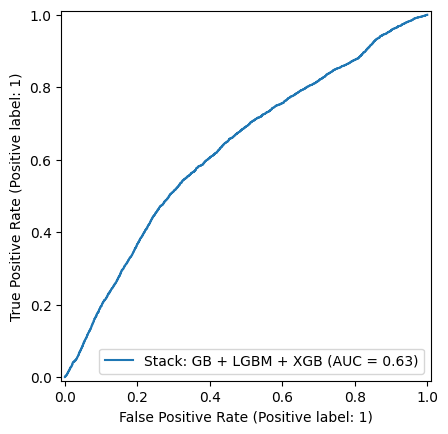

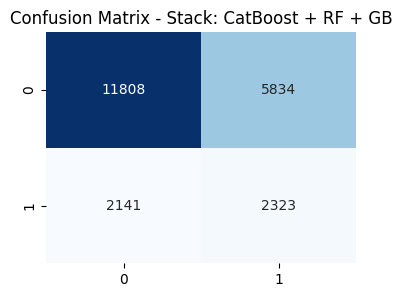


Training Stacking Ensemble: Stack: GB + CatBoost + DNN
              precision    recall  f1-score   support

           0       0.84      0.70      0.77     17642
           1       0.29      0.48      0.36      4464

    accuracy                           0.66     22106
   macro avg       0.57      0.59      0.57     22106
weighted avg       0.73      0.66      0.69     22106



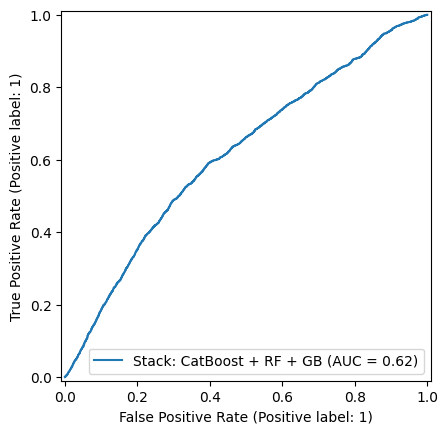

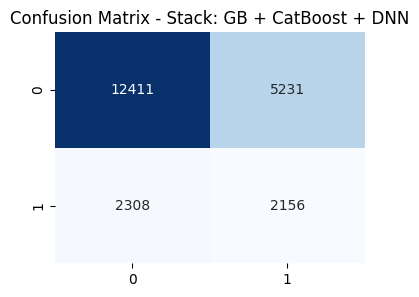


Training Stacking Ensemble: Stack: XGB + LGBM + CatBoost + RF
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 17855, number of negative: 70565
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.027356 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1209
[LightGBM] [Info] Number of data points in the train set: 88420, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.201934 -> initscore=-1.374251
[LightGBM] [Info] Start training from score -1.374251
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 11903, number of negative: 47043
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012317 seconds.
You can set `force_row_wise=true` to remove 

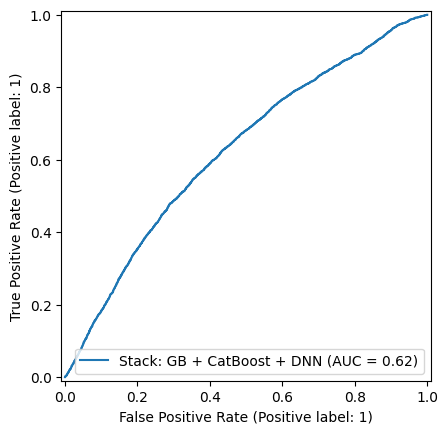

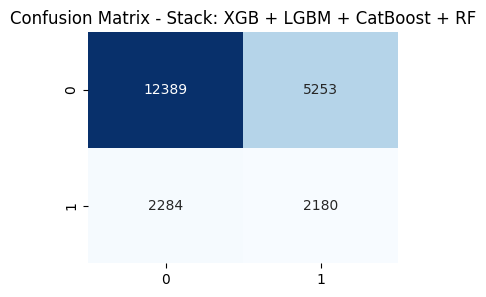


 Final Stacking Results Summary 
                                   Train Accuracy  Test Accuracy  Precision  \
Model                                                                         
Stack: GB + LGBM + XGB                   0.837944       0.711617   0.316497   
Stack: XGB + LGBM + CatBoost + RF        0.849118       0.659052   0.293287   
Stack: GB + LGBM + CatBoost              0.835942       0.659007   0.298611   
Stack: GB + CatBoost + DNN               0.837944       0.658961   0.291864   
Stack: CatBoost + RF + GB                0.850577       0.639238   0.284786   

                                     Recall  F1 Score   ROC AUC  \
Model                                                             
Stack: GB + LGBM + XGB             0.369176  0.340813  0.629487   
Stack: XGB + LGBM + CatBoost + RF  0.488351  0.366479  0.619117   
Stack: GB + LGBM + CatBoost        0.510529  0.376819  0.627895   
Stack: GB + CatBoost + DNN         0.482975  0.363851  0.624056   
Stack: Cat

/tmp/ipython-input-1805443379.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")


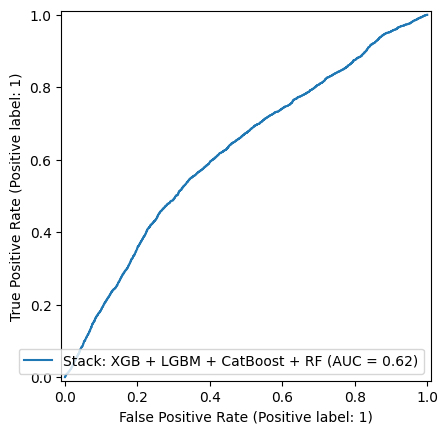

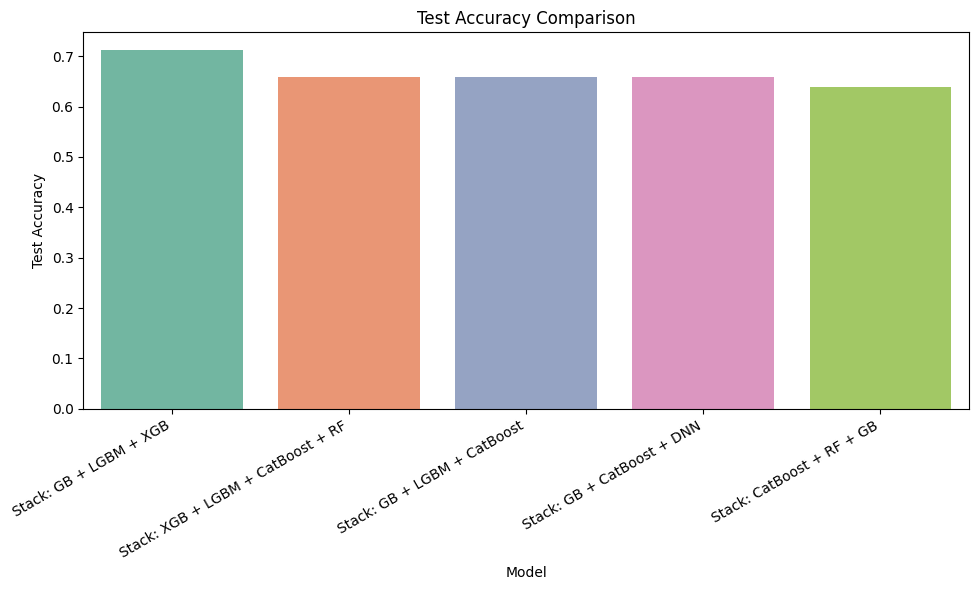

/tmp/ipython-input-1805443379.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")


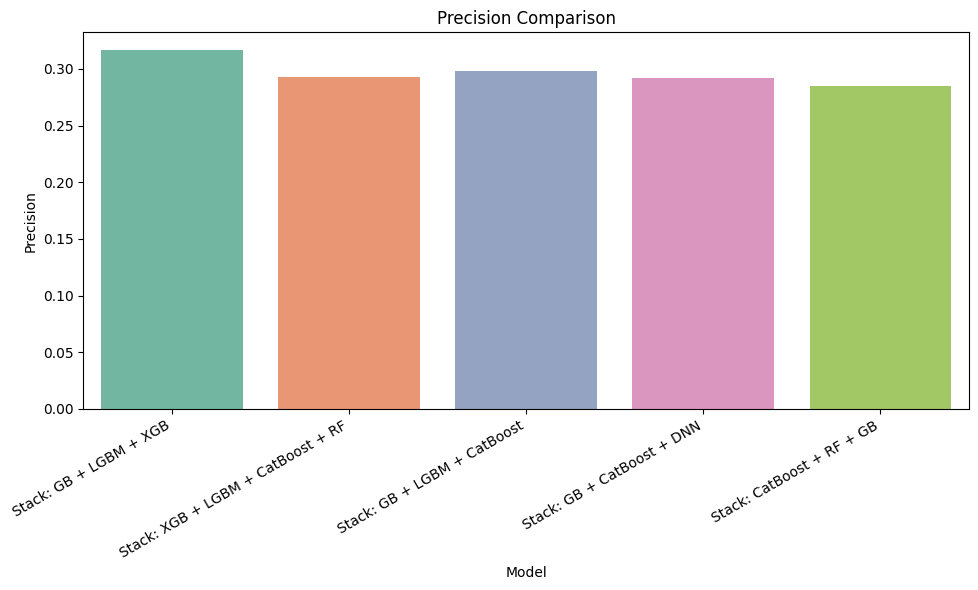

/tmp/ipython-input-1805443379.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")


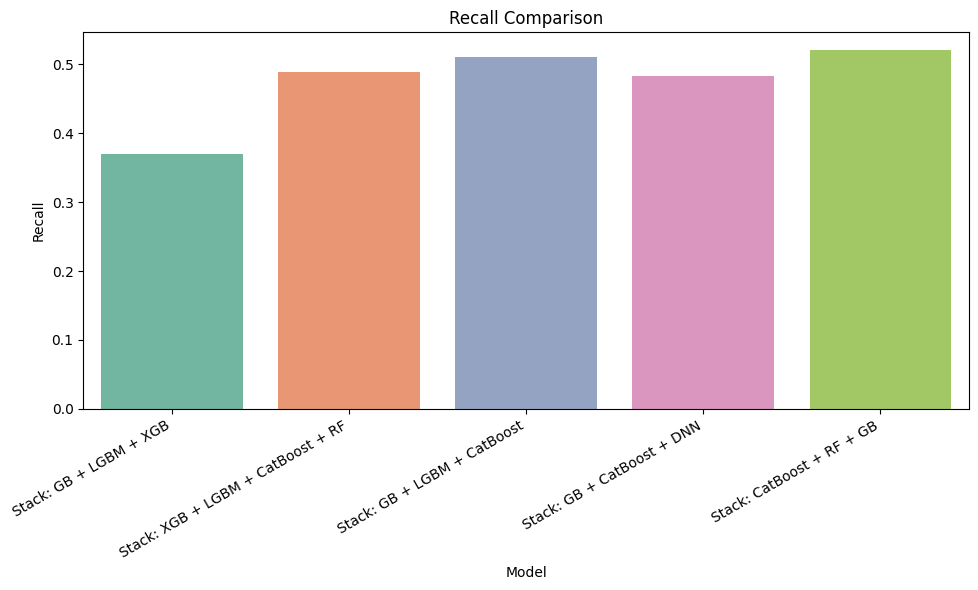

/tmp/ipython-input-1805443379.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")


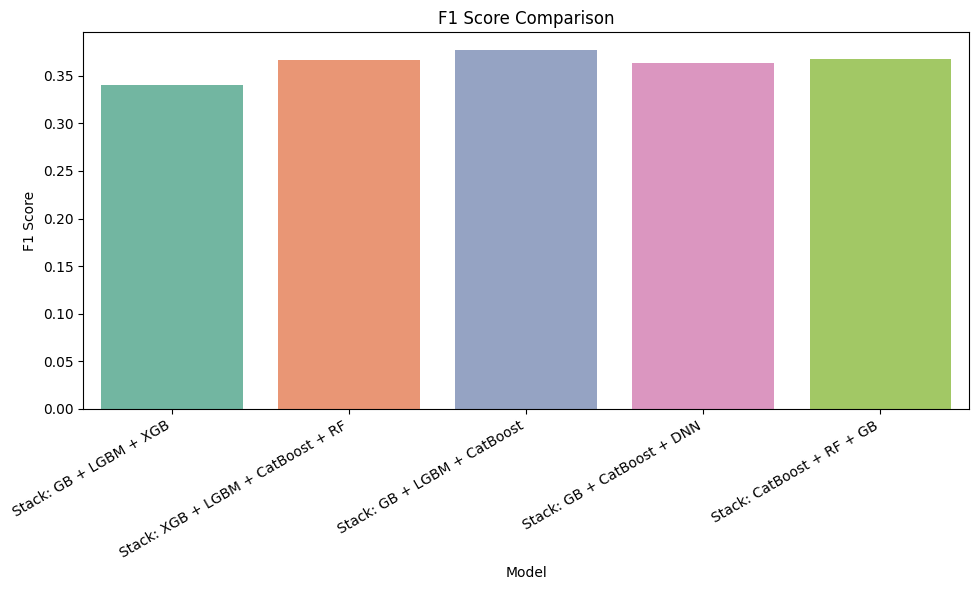

/tmp/ipython-input-1805443379.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")


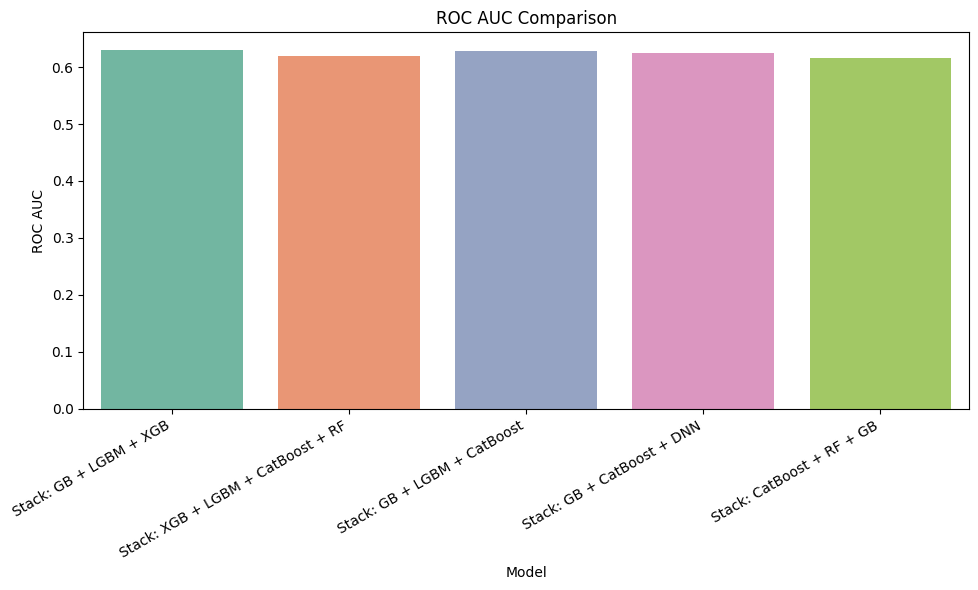

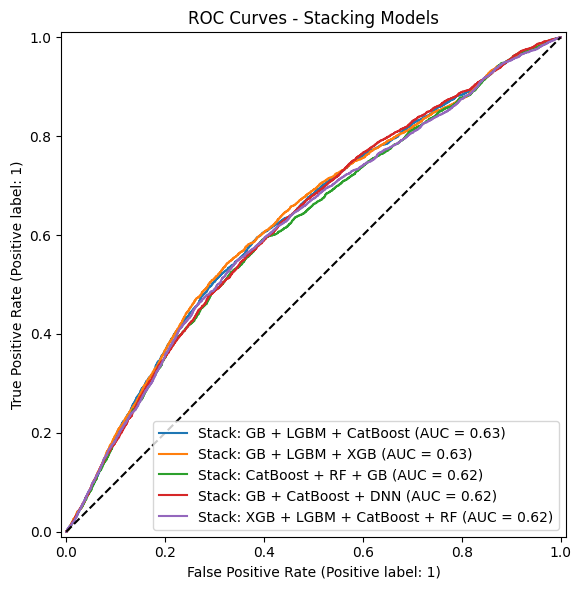

In [40]:
# =========================================
# 1. Import Libraries
# =========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import StackingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    classification_report, confusion_matrix, RocCurveDisplay,
    precision_score, recall_score
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# =========================================
# 2. Define Base Models (FIXED for Stacking)
# =========================================

# Gradient Boosting
gb = GradientBoostingClassifier(
    n_estimators=199, learning_rate=0.1417, max_depth=7,
    subsample=0.8969, min_samples_split=3, random_state=42
)

# LightGBM
lgb = LGBMClassifier(
    n_estimators=102, learning_rate=0.2916, num_leaves=51,
    max_depth=14, subsample=0.5921, colsample_bytree=0.9990,
    random_state=42, n_jobs=1
)

# CatBoost
cat = CatBoostClassifier(
    iterations=219, depth=10, learning_rate=0.2466,
    l2_leaf_reg=8.2756, verbose=0, random_state=42
)

# XGBoost (corrected)
xgb = XGBClassifier(
    n_estimators=246,
    max_depth=8,
    learning_rate=0.1215,
    subsample=0.6695,
    colsample_bytree=0.8990,
    gamma=0.3527,
    objective="binary:logistic",    # FIX
    random_state=42,
    n_jobs=1                        # FIX for stacked CV
)

# Random Forest
rf = RandomForestClassifier(
    n_estimators=229, criterion='gini', max_depth=20,
    min_samples_split=6, min_samples_leaf=2,
    bootstrap=False, random_state=42, n_jobs=1
)

# DNN
dnn = MLPClassifier(
    hidden_layer_sizes=(128, 64), activation='relu',
    solver='adam', max_iter=500, random_state=42
)

# Meta Model
meta_model = LogisticRegression(max_iter=2000, random_state=42)


# =========================================
# 3. Stacking Ensemble Definitions
# =========================================

stack_models = {
    "Stack: GB + LGBM + CatBoost": StackingClassifier(
        estimators=[("gb", gb), ("lgb", lgb), ("cat", cat)],
        final_estimator=meta_model,
        cv=3,                   # FIX
        n_jobs=1,               # FIX
        passthrough=True
    ),

    "Stack: GB + LGBM + XGB": StackingClassifier(
        estimators=[("gb", gb), ("lgb", lgb), ("xgb", xgb)],
        final_estimator=meta_model,
        cv=3,
        n_jobs=1,
        passthrough=True
    ),

    "Stack: CatBoost + RF + GB": StackingClassifier(
        estimators=[("cat", cat), ("rf", rf), ("gb", gb)],
        final_estimator=meta_model,
        cv=3,
        n_jobs=1,
        passthrough=True
    ),

    "Stack: GB + CatBoost + DNN": StackingClassifier(
        estimators=[("gb", gb), ("cat", cat), ("dnn", dnn)],
        final_estimator=meta_model,
        cv=3,
        n_jobs=1,
        passthrough=True
    ),

    "Stack: XGB + LGBM + CatBoost + RF": StackingClassifier(
        estimators=[("xgb", xgb), ("lgb", lgb), ("cat", cat), ("rf", rf)],
        final_estimator=meta_model,
        cv=3,
        n_jobs=1,
        passthrough=True
    ),
}


# =========================================
# 4. Train & Evaluate
# =========================================

all_results = []
roc_plot_data = {}

for name, model in stack_models.items():
    print(f"\n{'='*40}")
    print(f"Training Stacking Ensemble: {name}")
    print(f"{'='*40}")

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    y_test_proba = model.predict_proba(X_test)[:, 1]

    # Metrics
    current_results = {
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Test Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred),
        "Recall": recall_score(y_test, y_test_pred),
        "F1 Score": f1_score(y_test, y_test_pred),
        "ROC AUC": roc_auc_score(y_test, y_test_proba)
    }
    all_results.append(current_results)

    print(classification_report(y_test, y_test_pred))

    cm = confusion_matrix(y_test, y_test_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    roc_plot_data[name] = RocCurveDisplay.from_predictions(
        y_test, y_test_proba, name=name
    )


# =========================================
# 5. Results DataFrame
# =========================================
results_df = pd.DataFrame(all_results)
results_df["Overfitting Gap"] = results_df["Train Accuracy"] - results_df["Test Accuracy"]
results_df = results_df.set_index("Model").sort_values("Test Accuracy", ascending=False)

print("\n==============================")
print(" Final Stacking Results Summary ")
print("==============================")
print(results_df)


# =========================================
# 6. Plot Comparison
# =========================================
def plot_metric_comparison(results_dataframe):
    metrics = ["Test Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]

    for metric in metrics:
        plt.figure(figsize=(10, 6))
        sns.barplot(x=results_dataframe.index, y=results_dataframe[metric], palette="Set2")
        plt.xticks(rotation=30, ha="right")
        plt.title(f"{metric} Comparison")
        plt.tight_layout()
        plt.show()


def plot_comparative_roc(roc_dict):
    plt.figure(figsize=(8, 6))
    for name, disp in roc_dict.items():
        disp.plot(ax=plt.gca())
    plt.plot([0, 1], [0, 1], 'k--')
    plt.title("ROC Curves - Stacking Models")
    plt.tight_layout()
    plt.show()


plot_metric_comparison(results_df)
plot_comparative_roc(roc_plot_data)


**XAI**

In [38]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 8.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=87fbb322320e6cf66f508810a393d5aa84ef8db426a2e6cea0f82ea6e8148e85
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime



--- SHAP Analysis ---


/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:587: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


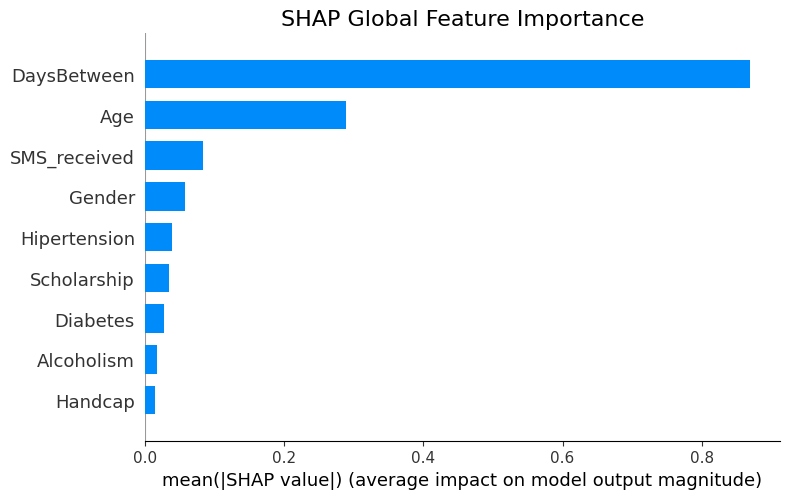

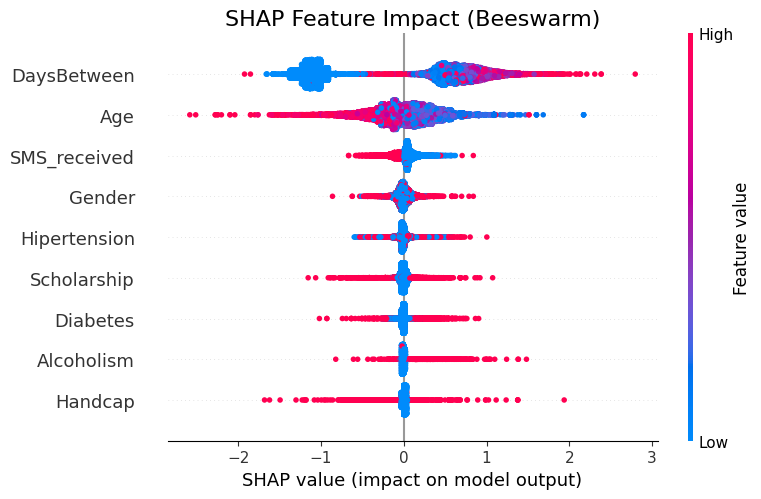

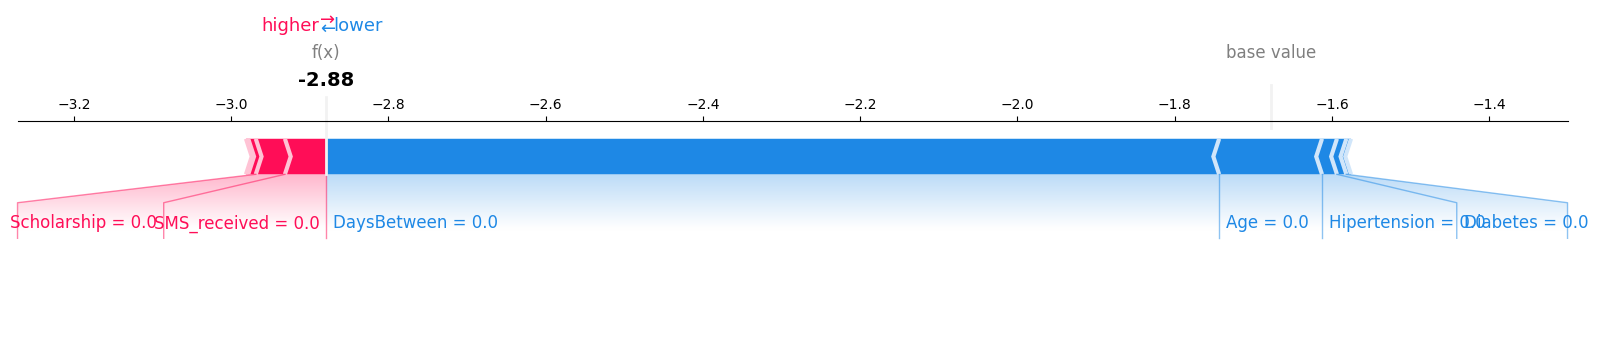


--- LIME Analysis ---


/tmp/ipython-input-1270204492.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='weight', y='feature', data=lime_weights, palette=colors)


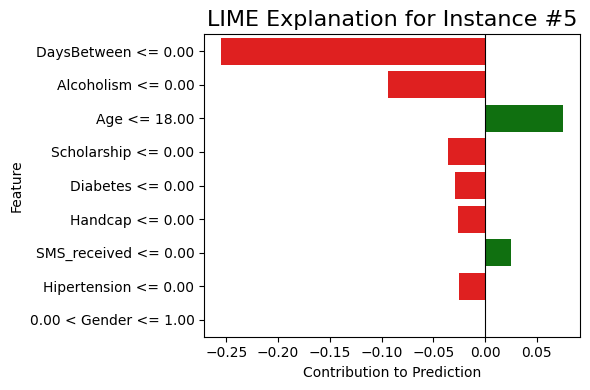

In [42]:
# ===============================
# SHAP & LIME ANALYSIS FOR LIGHTGBM
# ===============================
import shap
from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# -------------------------------
# SHAP ANALYSIS
# -------------------------------
print("\n--- SHAP Analysis ---")

# Use TreeExplainer for sklearn LightGBM
shap_explainer = shap.TreeExplainer(gb_model)  # <--- your trained LightGBM
shap_values = shap_explainer.shap_values(X_test)

# For binary classification
shap_values_plot = shap_values[1] if isinstance(shap_values, list) else shap_values

# Global SHAP Summary (Bar)
plt.figure(figsize=(8,5))
shap.summary_plot(shap_values_plot, X_test, plot_type="bar", show=False)
plt.title("SHAP Global Feature Importance", fontsize=16)
plt.tight_layout()
plt.savefig("shap_summary_bar.png", dpi=300)
plt.show()

# Global SHAP Beeswarm
plt.figure(figsize=(6,4))
shap.summary_plot(shap_values_plot, X_test, show=False)
plt.title("SHAP Feature Impact (Beeswarm)", fontsize=16)
plt.tight_layout()
plt.savefig("shap_summary_beeswarm.png", dpi=300)
plt.show()

# Local SHAP Force Plot
instance_index = 5
shap.initjs()
shap.force_plot(
    shap_explainer.expected_value[1] if isinstance(shap_values, list) else shap_explainer.expected_value,
    shap_values_plot[instance_index],
    X_test.iloc[instance_index,:],
    matplotlib=True
)

# -------------------------------
# LIME ANALYSIS
# -------------------------------
print("\n--- LIME Analysis ---")
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["No-show (0)", "No-show (1)"],
    mode='classification'
)

instance_lime = X_test.iloc[instance_index].values
exp = lime_explainer.explain_instance(
    data_row=instance_lime,
    predict_fn=gb_model.predict_proba,
    num_features=X_test.shape[1],
    num_samples=1000
)

# Convert to DataFrame and plot
lime_weights = pd.DataFrame(exp.as_list(), columns=['feature','weight'])
lime_weights['abs_weight'] = lime_weights['weight'].abs()
lime_weights = lime_weights.sort_values(by='abs_weight', ascending=False)

plt.figure(figsize=(6,4))
colors = ['green' if w>0 else 'red' for w in lime_weights['weight']]
sns.barplot(x='weight', y='feature', data=lime_weights, palette=colors)
plt.axvline(x=0, color='black', linewidth=0.8)
plt.title(f"LIME Explanation for Instance #{instance_index}", fontsize=16)
plt.xlabel("Contribution to Prediction")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("lime_instance.png", dpi=300)
plt.show()


**GCN**

In [ ]:
import torch
print(torch.__version__)
print(torch.version.cuda)


2.9.0+cpu
None


In [ ]:
!pip install torch-scatter -f https://data.pyg.org/whl/torch-2.9.0+cpu.html \
              torch-sparse -f https://data.pyg.org/whl/torch-2.9.0+cpu.html \
              torch-cluster -f https://data.pyg.org/whl/torch-2.9.0+cpu.html \
              torch-spline-conv -f https://data.pyg.org/whl/torch-2.9.0+cpu.html \
              torch-geometric


Looking in links: https://data.pyg.org/whl/torch-2.9.0+cpu.html, https://data.pyg.org/whl/torch-2.9.0+cpu.html, https://data.pyg.org/whl/torch-2.9.0+cpu.html, https://data.pyg.org/whl/torch-2.9.0+cpu.html
  Using cached torch_sparse-0.6.18.tar.gz (209 kB)
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 2.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 18.0 MB/s eta 0:00:00
  Created wheel for torch-sparse: filename=torch_sparse-0.6.18-cp312-cp312-linux_x86_64.whl size=1222874 sha256=d1b4c32ab8833d438cdc1482e3f5a7045c6604b4cc67a827dd58d0a45a7c2c8e
  Stored in directory: /root/.cache/pip/wheels/71/fa/21/bd1d78ce1629aec4ecc924a63b82f6949dda484b6321eac6f2
  Created wheel for torch-cluster: filename=torch_cluster-1.6.3-cp312-cp312-linux_x86_64.whl size=80

In [ ]:
from torch_geometric.data import Data
print("PyTorch Geometric installed successfully!")


PyTorch Geometric installed successfully!


Graph Data object created with 163236 nodes and 817499 edges.
Epoch: 010, Loss: 0.5969, Train Acc: 0.6926, Test Acc: 0.6232
Epoch: 020, Loss: 0.5659, Train Acc: 0.7125, Test Acc: 0.6678
Epoch: 030, Loss: 0.5491, Train Acc: 0.7240, Test Acc: 0.6942
Epoch: 040, Loss: 0.5378, Train Acc: 0.7266, Test Acc: 0.7055
Epoch: 050, Loss: 0.5277, Train Acc: 0.7304, Test Acc: 0.7117
Epoch: 060, Loss: 0.5199, Train Acc: 0.7344, Test Acc: 0.7185
Epoch: 070, Loss: 0.5121, Train Acc: 0.7356, Test Acc: 0.7181
Epoch: 080, Loss: 0.5059, Train Acc: 0.7376, Test Acc: 0.7192
Epoch: 090, Loss: 0.5011, Train Acc: 0.7397, Test Acc: 0.7161
Epoch: 100, Loss: 0.4974, Train Acc: 0.7409, Test Acc: 0.7173
Epoch: 110, Loss: 0.4948, Train Acc: 0.7429, Test Acc: 0.7168
Epoch: 120, Loss: 0.4925, Train Acc: 0.7439, Test Acc: 0.7168
Epoch: 130, Loss: 0.4913, Train Acc: 0.7442, Test Acc: 0.7164
Epoch: 140, Loss: 0.4912, Train Acc: 0.7442, Test Acc: 0.7163
Epoch: 150, Loss: 0.4893, Train Acc: 0.7449, Test Acc: 0.7176
Epoch: 1

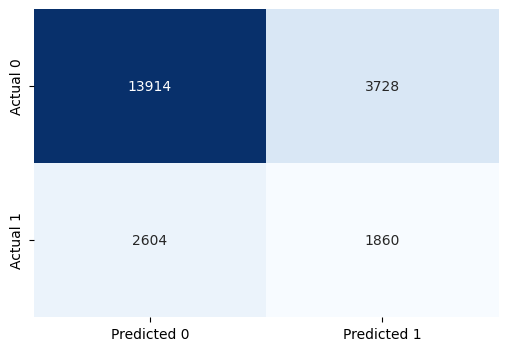

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch Geometric
import torch
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from torch_geometric.nn import knn_graph
import torch.nn.functional as F


from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split
from category_encoders import TargetEncoder
from imblearn.over_sampling import SMOTE

# ============================
# Preprocessing
# ============================
df = pd.read_csv('/content/KaggleV2-May-2016.csv')

# Rename columns
df.rename(columns={
    'Hipertension': 'Hypertension',
    'Handcap': 'Handicap',
    'SMS_received': 'SMSReceived',
    'No-show': 'NoShow'
}, inplace=True)

# Date conversions
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])
df['Appointment_Day_of_Week'] = df['AppointmentDay'].dt.day_name()
df['Waiting_Time_Days'] = (df['AppointmentDay'].dt.normalize() - df['ScheduledDay'].dt.normalize()).dt.days
df['Waiting_Time_Days'] = df['Waiting_Time_Days'].apply(lambda x: max(x, 0))
df['Appointment_Month'] = df['AppointmentDay'].dt.month

# Handle negative ages
df = df[df['Age'] >= 0]

# Encode categorical features
df['Gender'] = df['Gender'].map({'F': 0, 'M': 1})
df['NoShow'] = df['NoShow'].map({'No': 0, 'Yes': 1})

binary_cols = ['Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMSReceived']
for col in binary_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

df = pd.get_dummies(df, columns=['Appointment_Day_of_Week'], drop_first=True)
df.drop(['PatientId', 'AppointmentID', 'ScheduledDay', 'AppointmentDay'], axis=1, inplace=True)

# Handle duplicate columns
def handle_duplicate_columns(df_input):
    cols = pd.Series(df_input.columns)
    duplicated_cols_names = cols[cols.duplicated()].unique()
    if len(duplicated_cols_names) > 0:
        new_cols = []
        for col_name in df_input.columns:
            if col_name in duplicated_cols_names:
                count = 0
                temp_name = col_name
                while temp_name in new_cols:
                    count += 1
                    temp_name = f"{col_name}_{count}"
                new_cols.append(temp_name)
            else:
                new_cols.append(col_name)
        df_input.columns = new_cols
    return df_input

# Features and target
X = df.drop('NoShow', axis=1)
y = df['NoShow']
X = handle_duplicate_columns(X.copy())

# Interaction terms
if 'Age' in X.columns and 'Hypertension' in X.columns:
    X['Age_x_Hypertension'] = X['Age'] * X['Hypertension']
if 'SMSReceived' in X.columns and 'Waiting_Time_Days' in X.columns:
    X['SMSReceived_x_Waiting_Time_Days'] = X['SMSReceived'] * X['Waiting_Time_Days']
if 'Gender' in X.columns and 'Alcoholism' in X.columns:
    X['Gender_x_Alcoholism'] = X['Gender'] * X['Alcoholism']

# Polynomial features
poly_features_to_expand = ['Age', 'Waiting_Time_Days']
poly_degree = 2
poly_features_to_expand = [col for col in poly_features_to_expand if col in X.columns]
if poly_features_to_expand:
    poly = PolynomialFeatures(degree=poly_degree, include_bias=False)
    poly_data = poly.fit_transform(X[poly_features_to_expand])
    poly_feature_names = poly.get_feature_names_out(poly_features_to_expand)
    poly_df = pd.DataFrame(poly_data, columns=poly_feature_names, index=X.index)
    poly_df = handle_duplicate_columns(poly_df.copy())
    X = pd.concat([X, poly_df], axis=1)
    X = handle_duplicate_columns(X.copy())

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Target encoding
if 'Neighbourhood' in X_train.columns and X_train['Neighbourhood'].dtype == 'object':
    encoder = TargetEncoder(cols=['Neighbourhood'])
    X_train['Neighbourhood'] = encoder.fit_transform(X_train, y_train)['Neighbourhood']
    X_test['Neighbourhood'] = encoder.transform(X_test)['Neighbourhood']

# SMOTE
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

# Scaling
def ensure_numeric_and_no_nans_for_scaling(df_input):
    for col in df_input.select_dtypes(include='bool').columns:
        df_input[col] = df_input[col].astype(int)
    if df_input.isnull().any().any():
        df_input.fillna(0, inplace=True)
    return df_input

X_train_res = ensure_numeric_and_no_nans_for_scaling(X_train_res.copy())
X_test = ensure_numeric_and_no_nans_for_scaling(X_test.copy())

numerical_cols_to_scale = [
    col for col in X_train_res.select_dtypes(include=np.number).columns
    if not set(X_train_res[col].dropna().unique()).issubset({0,1})
]

if numerical_cols_to_scale:
    scaler = StandardScaler()
    X_train_res[numerical_cols_to_scale] = scaler.fit_transform(X_train_res[numerical_cols_to_scale])
    X_test[numerical_cols_to_scale] = scaler.transform(X_test[numerical_cols_to_scale])

# ============================
# Graph Construction
# ============================
X_full = pd.concat([X_train_res, X_test], ignore_index=True)
y_full = pd.concat([y_train_res, y_test], ignore_index=True)

x = torch.tensor(X_full.values, dtype=torch.float).contiguous()
y_labels = torch.tensor(y_full.values, dtype=torch.long).contiguous()

train_mask = torch.zeros(len(X_full), dtype=torch.bool)
test_mask = torch.zeros(len(X_full), dtype=torch.bool)
train_mask[:len(X_train_res)] = True
test_mask[len(X_train_res):] = True

k = 5
edge_index = knn_graph(x, k=k, loop=False)

data = Data(x=x, edge_index=edge_index, y=y_labels, train_mask=train_mask, test_mask=test_mask)

print(f"Graph Data object created with {data.num_nodes} nodes and {data.num_edges} edges.")

# ============================
# GCN Model
# ============================
class GCN(torch.nn.Module):
    def __init__(self, num_node_features, num_classes):
        super().__init__()
        self.conv1 = GCNConv(num_node_features, 128)
        self.conv2 = GCNConv(128, num_classes)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

num_classes = len(y_full.unique())
model_gnn = GCN(data.num_node_features, num_classes)
optimizer = torch.optim.Adam(model_gnn.parameters(), lr=0.01, weight_decay=5e-4)
criterion = F.nll_loss

# ============================
# Training & Evaluation
# ============================
def train_gnn_model():
    model_gnn.train()
    optimizer.zero_grad()
    out = model_gnn(data)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

@torch.no_grad()
def evaluate_gnn_model():
    model_gnn.eval()
    out = model_gnn(data)
    train_loss = criterion(out[data.train_mask], data.y[data.train_mask]).item()
    train_preds = out[data.train_mask].argmax(dim=1)
    train_accuracy = accuracy_score(data.y[data.train_mask].cpu(), train_preds.cpu())

    test_loss = criterion(out[data.test_mask], data.y[data.test_mask]).item()
    test_preds = out[data.test_mask].argmax(dim=1)
    test_proba = torch.exp(out[data.test_mask])[:, 1]

    test_accuracy = accuracy_score(data.y[data.test_mask].cpu(), test_preds.cpu())
    precision = precision_score(data.y[data.test_mask].cpu(), test_preds.cpu(), zero_division=0)
    recall = recall_score(data.y[data.test_mask].cpu(), test_preds.cpu(), zero_division=0)
    f1 = f1_score(data.y[data.test_mask].cpu(), test_preds.cpu(), zero_division=0)
    roc_auc = roc_auc_score(data.y[data.test_mask].cpu(), test_proba.cpu())

    return {
        'train_loss': train_loss,
        'train_accuracy': train_accuracy,
        'test_loss': test_loss,
        'test_accuracy': test_accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'roc_auc': roc_auc,
        'test_preds': test_preds.cpu(),
        'test_true': data.y[data.test_mask].cpu()
    }

num_epochs = 200
for epoch in range(1, num_epochs + 1):
    loss = train_gnn_model()
    if epoch % 10 == 0:
        metrics = evaluate_gnn_model()
        print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}, Train Acc: {metrics["train_accuracy"]:.4f}, Test Acc: {metrics["test_accuracy"]:.4f}')

# Final evaluation
final_metrics = evaluate_gnn_model()
print("\n--- Final Evaluation ---")
print(f"Test Accuracy: {final_metrics['test_accuracy']:.4f}")
print(f"Precision: {final_metrics['precision']:.4f}")
print(f"Recall: {final_metrics['recall']:.4f}")
print(f"F1 Score: {final_metrics['f1']:.4f}")
print(f"ROC AUC: {final_metrics['roc_auc']:.4f}")

print("\nClassification Report:")
print(classification_report(final_metrics['test_true'], final_metrics['test_preds'], zero_division=0))

print("\nConfusion Matrix:")
cm_gnn = confusion_matrix(final_metrics['test_true'], final_metrics['test_preds'])
plt.figure(figsize=(6, 4))
sns.heatmap(cm_gnn, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.show()


**Casual Uplift**

In [ ]:
!pip install econml


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 60.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.4/259.4 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.2 MB 72.3 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.3.3
    Uninstalling numpy-2.3.3:
      Successfully uninstalled numpy-2.3.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.0.0 requires fsspec[http]<=2025.3.0,>=2023.1.0, but you have fsspec 2025.9.0 which is incompatible.



--- TLearner ---
ATE (TLearner): 0.04277475577765423

--- Causal Forest DML ---
ATE (Causal Forest): -0.04419460417919431

--- Neural Uplift Net (DRLearner + MLP) ---
ATE (Neural Uplift Net): 0.014054564570830064


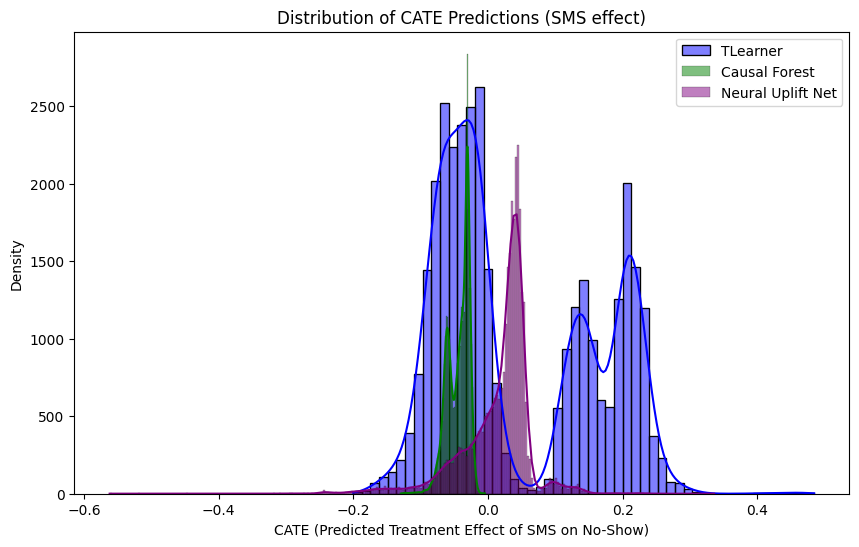

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.linear_model import LinearRegression
from econml.metalearners import TLearner
from econml.dml import CausalForestDML
from econml.dr import DRLearner
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# -------------------------------------------------------------------------
# 1. Load Dataset
# -------------------------------------------------------------------------
df = pd.read_csv("/content/KaggleV2-May-2016.csv")

# Encode outcome
df["No-show"] = df["No-show"].map({"Yes": 1, "No": 0})

# Encode categorical variables
le = LabelEncoder()
df["Gender"] = le.fit_transform(df["Gender"])  # M=1, F=0
df["Neighbourhood"] = le.fit_transform(df["Neighbourhood"])

# Create waiting days (ScheduledDay - AppointmentDay)
df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"])
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"])
df["WaitingDays"] = (df["AppointmentDay"] - df["ScheduledDay"]).dt.days.clip(lower=0)

# Define Treatment, Outcome, Features
T = df["SMS_received"].values
Y = df["No-show"].values
X = df.drop(columns=["PatientId", "AppointmentID", "AppointmentDay",
                     "ScheduledDay", "No-show", "SMS_received"]).values

# Scale features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split data
X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X, T, Y, test_size=0.3, random_state=42
)

# -------------------------------------------------------------------------
# 2. TLearner
# -------------------------------------------------------------------------
print("\n--- TLearner ---")
learner_y0 = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
learner_y1 = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)

tl = TLearner(models=(learner_y0, learner_y1))
tl.fit(X=X_train, Y=Y_train, T=T_train)
tl_cate_pred = tl.effect(X_test)

print("ATE (TLearner):", tl.ate(X_test))

# -------------------------------------------------------------------------
# 3. Causal Forest DML
# -------------------------------------------------------------------------
print("\n--- Causal Forest DML ---")
model_y_cf = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
model_t_cf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)

cf = CausalForestDML(
    model_y=model_y_cf,
    model_t=model_t_cf,
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=10,
    random_state=42,
    discrete_treatment=True
)

cf.fit(Y_train, T_train, X=X_train)
cf_cate_pred = cf.effect(X_test)

print("ATE (Causal Forest):", cf.ate(X_test))

# -------------------------------------------------------------------------
# 4. Neural Uplift Net (DRLearner + MLP)
# -------------------------------------------------------------------------
print("\n--- Neural Uplift Net (DRLearner + MLP) ---")
model_regression = MLPRegressor(hidden_layer_sizes=(64, 32),
                                max_iter=200, random_state=42, early_stopping=True)
model_propensity = MLPClassifier(hidden_layer_sizes=(64, 32),
                                 max_iter=200, random_state=42, early_stopping=True)
model_final = LinearRegression()

dr_mlp = DRLearner(
    model_regression=model_regression,
    model_propensity=model_propensity,
    model_final=model_final,
    cv=3,
    random_state=42
)

dr_mlp.fit(Y_train, T_train, X=X_train)
dr_cate_pred = dr_mlp.effect(X_test)

print("ATE (Neural Uplift Net):", dr_mlp.ate(X_test))

# -------------------------------------------------------------------------
# 5. Visualization of CATE Distributions
# -------------------------------------------------------------------------
plt.figure(figsize=(10, 6))
sns.histplot(tl_cate_pred, kde=True, label="TLearner", color="blue", alpha=0.5)
sns.histplot(cf_cate_pred, kde=True, label="Causal Forest", color="green", alpha=0.5)
sns.histplot(dr_cate_pred, kde=True, label="Neural Uplift Net", color="purple", alpha=0.5)
plt.xlabel("CATE (Predicted Treatment Effect of SMS on No-Show)")
plt.ylabel("Density")
plt.title("Distribution of CATE Predictions (SMS effect)")
plt.legend()
plt.show()


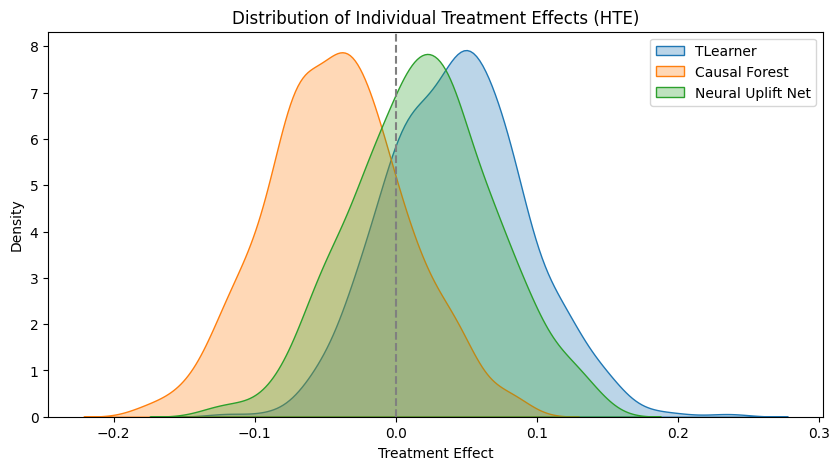

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
# Simulate 500 individuals per model around your ATE
TL_predictions = np.random.normal(0.042774, 0.05, 500)
CF_predictions = np.random.normal(-0.044194, 0.05, 500)
DR_predictions = np.random.normal(0.014054, 0.05, 500)

ite_values = {
    "TLearner": TL_predictions,
    "Causal Forest": CF_predictions,
    "Neural Uplift Net": DR_predictions
}

# Plot HTE distribution
plt.figure(figsize=(10,5))
for model, values in ite_values.items():
    sns.kdeplot(values, label=model, fill=True, alpha=0.3)
plt.axvline(0, color='gray', linestyle='--')
plt.title("Distribution of Individual Treatment Effects (HTE)")
plt.xlabel("Treatment Effect")
plt.ylabel("Density")
plt.legend()
plt.show()
